# 18 · Boyut İndirgeme - İleri Yöntemler (Dimensionality Reduction: Kernel PCA, LDA, NMF, ICA, t-SNE, UMAP)

> **Bu notebook'ta ne öğreneceğiz?**
> PCA'yı (Linear-Algebra-lab) biliyoruz: veriyi **varyansı en çok koruyan doğrusal eksenlere**
> döndürür. Ama PCA'nın üç sınırı var: (1) **doğrusal** — kıvrımlı yapıları düzleştiremez,
> (2) **denetimsiz** — sınıf etiketini hiç kullanmaz, (3) bileşenleri **negatif ve "anlamsız"**
> karışımlardır — yorumlanamaz. Bu notebook her sınırı aşan bir yöntem ailesini anlatıyor;
> her birini önce **küçük, elle hesaplanabilir bir örnekle**, sonra gerçek veriyle öğreneceğiz:
>
> 1. **LDA (Linear Discriminant Analysis):** Etiketleri kullanan **denetimli** boyut indirgeme
>    — sınıfları en iyi ayıran ekseni arar.
> 2. **Kernel PCA:** Kernel hilesiyle PCA'yı **doğrusal olmayan** yapılara taşır.
> 3. **NMF (Non-negative Matrix Factorization):** Her şeyi **eksi olmayan "parçaların toplamı"**
>    olarak yazar — yüz = göz + burun + ağız, belge = konu karışımı.
> 4. **ICA (Independent Component Analysis):** Karışmış sinyalleri **bağımsız kaynaklara** ayırır
>    (kokteyl partisi problemi).
> 5. **t-SNE ve UMAP:** Yüksek boyutlu veriyi 2B'de **görselleştirmek** için komşuluk-koruyan
>    manifold yöntemleri.
>
> Çekirdek mantığı **sıfırdan** kodlayıp scikit-learn / `umap-learn` ile doğrulayacağız ve
> sonda hepsini aynı veri üzerinde **sayısal metriklerle** (trustworthiness, kNN doğruluğu, süre)
> karşılaştıracağız.
>
> **Önkoşul:** Linear-Algebra-lab (özdeğer/SVD, PCA), 01 · Veri Ön İşleme (ölçekleme),
> 16-17 · Kümeleme (embedding üzerinde kümeleme fikri), 03 · Doğrusal Sınıflandırma (LDA/QDA'nın
> sınıflandırıcı olarak kullanımı).
>
> **Veri:** `Fashion-MNIST` test kümesi (Zalando; 10.000 giysi görüntüsü, 784 piksel, 10 sınıf —
> LDA/t-SNE/UMAP için), `Olivetti Faces` (AT&T Laboratuvarı; 400 yüz, 4096 piksel — NMF "parçalar"
> ve ICA için), `20 Newsgroups` (6 kategori, 5.604 haber grubu yazısı — NMF ile **konu bulma**
> için) ve yöntemleri sezgisel göstermek için sentetik veriler (`make_circles`, karışık sinyaller).
> Üçü de serinin önceki notebook'larında **kullanılmamış** veri setleri.
>
> **Araçlar:** `sklearn.decomposition` (`PCA`, `KernelPCA`, `NMF`, `FastICA`),
> `sklearn.discriminant_analysis`, `sklearn.manifold` (`TSNE`, `trustworthiness`), `umap-learn`,
> R (`kernlab`, `fastICA`, `Rtsne`, `uwot`), DuckDB (SQL).

## 1 · Neden "İleri" Boyut İndirgeme? Bir Harita

**İki farklı amaç.** Boyut indirgemeyi iki farklı işte kullanırız ve yöntem seçimi amaca bağlıdır:

| Amaç | Soru | Örnek |
|---|---|---|
| **Özellik çıkarımı / sıkıştırma** (feature extraction) | "Modele daha az, daha temiz özellik versin" | 784 pikseli 50 sayıya indirip sınıflandırıcıyı hızlandırmak |
| **Görselleştirme / keşif** | "Veriyi 2B'de gözümle göreyim" | Müşteri segmentlerinin ya da hücre tiplerinin haritası |

**Harita:** Hangi yöntem hangi PCA sınırını aşıyor?

| Yöntem | Doğrusal mı? | Etiket kullanır mı? | Ne üretir? | Yeni veriye uygulanır mı? |
|---|---|---|---|---|
| PCA (hatırlatma) | Evet | Hayır | Varyansı koruyan dik eksenler | Evet (`transform`) |
| **LDA** | Evet | **Evet** | Sınıfları en iyi ayıran eksenler (en çok $C-1$ tane) | Evet |
| **Kernel PCA** | **Hayır** (kernel ile) | Hayır | Özellik uzayında varyans eksenleri | Evet (kernel satırı ile) |
| **NMF** | Evet (ama $\ge 0$ kısıtı) | Hayır | Parçalar ($W$) ve katsayılar ($H$) | Evet (ek optimizasyonla) |
| **ICA** | Evet | Hayır | İstatistiksel olarak **bağımsız** kaynaklar | Evet |
| **t-SNE** | **Hayır** | Hayır | 2B/3B harita (komşulukları korur) | **Hayır** (klasik) |
| **UMAP** | **Hayır** | Hayır (isteğe bağlı: evet) | 2B..$d$ harita | **Evet** (`transform`) |

**Endüstride nerede kullanılır?** Genomikte tek-hücre RNA-seq verisi (20.000 gen) UMAP/t-SNE ile hücre
tiplerine göre haritalanır; bankacılıkta LDA, kredi başvurusunu "temerrüt/temerrüt-değil" diye ayıran
ölçek-bağımsız bir skor üretir; müzik/konuşma işlemede ICA mikrofon karışımlarını ayırır; metin
madenciliğinde NMF haber arşivinden **konu** çıkarır; kimya/spektroskopide NMF, karışım spektrumunu
saf bileşen spektrumlarına ayırır.

## 2 · PCA Hatırlatma (ve Sınırları)

$\mathbf{X}$ ($n\times p$) ortalaması çıkarılmış veri olsun. PCA, kovaryans matrisi
$\mathbf{S}=\frac{1}{n-1}\mathbf{X}^\top\mathbf{X}$'in özvektörlerini ($\mathbf{v}_1,\mathbf{v}_2,\dots$) bulur;
$k$-boyutlu temsil $\mathbf{Z}=\mathbf{X}\mathbf{V}_k$. Aynı sonuç **SVD** ile de gelir:
$\mathbf{X}=\mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$ ⇒ $\mathbf{Z}=\mathbf{U}_k\boldsymbol{\Sigma}_k$ ve
$\lambda_j=\sigma_j^2/(n-1)$. Açıklanan varyans oranı: $\text{EVR}_j=\lambda_j/\sum_i\lambda_i$.

**Üç sınır (bu notebook'un motivasyonu):**

1. **Doğrusal:** İç içe iki halka (çember) verisinde en büyük varyans yönü halkaları ayırmaz — ikisi de
   aynı merkezli. Doğrusal bir izdüşüm onları **ayıramaz** → Kernel PCA (§4).
2. **Denetimsiz:** En büyük varyans yönü, sınıfları ayıran yön olmak zorunda değildir (örn. ağırlık
   ölçeği ne kadar büyükse o eksen o kadar baskın). → LDA (§3).
3. **Yorumlanamaz bileşenler:** PCA bileşenleri artı/eksi işaretli karışımlardır; "yüz" PCA ile
   "0.3·(bir yüz) − 0.2·(başka yüz)..." diye yazılır (eigenface). → NMF (§5).

## 3 · LDA: Etiketi Kullanan Boyut İndirgeme

### 3.1 Sezgi
PCA "veri nerede **en çok yayılıyor**?" diye sorar; LDA (Fisher, 1936) "sınıflar nerede **en iyi ayrılıyor**?"
diye sorar. İki sınıfın ortalamaları birbirinden uzak, ama her sınıfın **kendi içinde** dar olduğu yönü ararız.

### 3.2 Formüller
Sınıf $c$'nin ortalaması $\mathbf{m}_c$, genel ortalama $\mathbf{m}$, sınıf boyutu $n_c$ olsun.

- **Sınıf-içi saçılım:** $\mathbf{S}_W=\sum_c\sum_{i\in c}(\mathbf{x}_i-\mathbf{m}_c)(\mathbf{x}_i-\mathbf{m}_c)^\top$
- **Sınıflar-arası saçılım:** $\mathbf{S}_B=\sum_c n_c(\mathbf{m}_c-\mathbf{m})(\mathbf{m}_c-\mathbf{m})^\top$
- **Fisher ölçütü:** $J(\mathbf{w})=\dfrac{\mathbf{w}^\top\mathbf{S}_B\mathbf{w}}{\mathbf{w}^\top\mathbf{S}_W\mathbf{w}}$ — pay: sınıf merkezleri arası uzaklık, payda: sınıf içi yayılım.
- $J$'yi maksimize eden $\mathbf{w}$'ler, $\mathbf{S}_W^{-1}\mathbf{S}_B$ matrisinin en büyük özdeğerlerine ait özvektörlerdir.
- $\mathrm{rank}(\mathbf{S}_B)\le C-1$ olduğundan **en fazla $C-1$ anlamlı eksen** vardır (10 sınıf ⇒ en çok 9 boyut).

### 3.3 🔍 Somut örnek: iki sınıf, iki öznitelik (elle)
Sınıf A: $(1,2),(2,3),(3,3)$ — ortalama $\mathbf{m}_A=(2,\ 2.667)$. Sınıf B: $(3,1),(4,2),(5,2)$ — ortalama $\mathbf{m}_B=(4,\ 1.667)$.
Sınıf-içi saçılımların toplamı $\mathbf{S}_W=\begin{pmatrix}4&2\\2&1.333\end{pmatrix}$.
İki sınıf için Fisher yönü kapalı formda $\mathbf{w}\propto\mathbf{S}_W^{-1}(\mathbf{m}_A-\mathbf{m}_B)$:

$$\mathbf{w}=\begin{pmatrix}4&2\\2&1.333\end{pmatrix}^{-1}\begin{pmatrix}-2\\1\end{pmatrix}=\begin{pmatrix}-3.5\\6\end{pmatrix}\ \Rightarrow\ \text{birim}: (-0.504,\ 0.864).$$

Bu yöne izdüşüm (ölçeksiz $\mathbf{w}^\top\mathbf{x}$): A için $\{8.5,\ 11,\ 7.5\}$, B için $\{-4.5,\ -2,\ -5.5\}$
— sınıflar **tamamen ayrık**. Dikkat: sınıf ortalamalarını birleştiren düz çizgi $(-2,1)$ yönündedir;
Fisher yönü $(-3.5,6)$ ondan **farklıdır** çünkü $\mathbf{S}_W^{-1}$ sınıf-içi kovaryansı hesaba katarak yönü "döndürür".
Adım 2'de bu hesabı kodla birebir yeniden üreteceğiz.

**Endüstride nerede kullanılır?** Yüz tanımada klasik **Fisherfaces** (Belhumeur ve ark., 1997); kredi riskinde
Altman'ın **Z-skoru** (1968) — iflas eden/etmeyen firmaları ayıran bir LDA'dır; tıbbi tanıda (EEG/EKG sınıflandırma)
ve spektroskopide ayrıştırıcı öznitelik çıkarımı olarak. **Uyarı:** $p>n$ iken (örn. 784 piksel ama az örnek)
$\mathbf{S}_W$ tekildir; önce PCA ile boyutu düşürüp sonra LDA uygulanır (Adım 2'de yapacağız).

## 4 · Kernel PCA: Doğrusal Olmayan PCA

### 4.1 Fikir
Veriyi önce **yüksek boyutlu bir özellik uzayına** $\phi(\mathbf{x})$ taşı, orada PCA yap. Bu uzayı **hiç hesaplamadan**,
sadece **kernel fonksiyonu** $k(\mathbf{x},\mathbf{y})=\phi(\mathbf{x})^\top\phi(\mathbf{y})$ ile çalışırız (SVM'deki kernel hilesi, 07).
Yaygın kernel'lar: RBF $k=\exp(-\gamma\lVert\mathbf{x}-\mathbf{y}\rVert^2)$, polinom, sigmoid, cosine.

### 4.2 Algoritma
1. Kernel matrisi $K_{ij}=k(\mathbf{x}_i,\mathbf{x}_j)$ ($n\times n$).
2. **Merkezle:** $\tilde{K}=\mathbf{J}K\mathbf{J}$, $\mathbf{J}=\mathbf{I}-\tfrac{1}{n}\mathbf{1}\mathbf{1}^\top$ (özellik uzayında ortalamayı çıkarmanın kernel karşılığı).
3. $\tilde{K}$'nın özdeğer-özvektörlerini bul: $\tilde{K}\mathbf{a}_j=\lambda_j\mathbf{a}_j$.
4. Eğitim noktalarının $j$-inci bileşen değeri: $z_{ij}=\sqrt{\lambda_j}\,a_{ij}$.
5. **Yeni nokta** $\mathbf{x}_*$ için: $z_{*j}=\dfrac{1}{\sqrt{\lambda_j}}\sum_i a_{ij}\,\tilde{k}(\mathbf{x}_i,\mathbf{x}_*)$ (merkezlenmiş kernel satırı).

### 4.3 🔍 Somut örnek: 3 nokta, RBF
Tek boyutlu $x=\{0,\ 1,\ 3\}$, $\gamma=0.5$. Kernel: $K_{12}=e^{-0.5\cdot1}=0.6065,\ K_{13}=e^{-0.5\cdot9}=0.0111,\ K_{23}=e^{-0.5\cdot4}=0.1353$:

$$K=\begin{pmatrix}1&0.6065&0.0111\\0.6065&1&0.1353\\0.0111&0.1353&1\end{pmatrix}\ \xrightarrow{\ \mathbf{J}K\mathbf{J}\ }\ \tilde{K}=\begin{pmatrix}0.422&-0.013&-0.410\\-0.013&0.339&-0.327\\-0.410&-0.327&0.736\end{pmatrix}.$$

Özdeğerler $\lambda=(1.112,\ 0.386,\ 0)$ (merkezleme yüzünden biri tam sıfır). Birinci bileşen değerleri
$\sqrt{1.112}\cdot\mathbf{a}_1=(-0.502,\ -0.354,\ 0.857)$: sıralama $x=0,1$ yakın, $x=3$ uzakta — uzaklık yapısı korunuyor.
Adım 3'te bu hesabı kodla birebir yeniden üreteceğiz.

### 4.4 $\gamma$ ve kısıtlar
$\gamma$ küçükse kernel geniş → neredeyse doğrusal PCA; $\gamma$ büyükse her nokta kendi adası (yalnızca kendisine benzer) →
bileşenler gürültüye döner. **Kısıtlar:** (a) $n\times n$ matris → bellek/hesap $O(n^2)$–$O(n^3)$, büyük veride pahalı;
(b) **pre-image problemi:** özellik uzayındaki sonuçtan orijinal uzaya geri dönmek tek anlamlı değildir (gürültü giderme için yaklaşık çözümler var);
(c) $\gamma$ ve kernel seçimi hiperparametredir.

**Endüstride nerede kullanılır?** Gürültü giderme (el yazısı rakamlarda, Mika ve ark. 1999), biyoinformatikte doğrusal olmayan
gen-ifade yapıları, ve sınıflandırıcıdan önce doğrusal olmayan öznitelik üretimi olarak.

## 5 · NMF: Eksi Olmayan "Parçaların Toplamı"

### 5.1 Fikir
$\mathbf{V}\in\mathbb{R}_{\ge0}^{n\times p}$ (piksel yoğunluğu, kelime sayısı, spektrum şiddeti... hepsi $\ge0$) olsun:

$$\mathbf{V}\approx\mathbf{W}\mathbf{H},\qquad \mathbf{W}\in\mathbb{R}_{\ge0}^{n\times r},\ \mathbf{H}\in\mathbb{R}_{\ge0}^{r\times p}.$$

$\mathbf{H}$'nin satırları **"parçalar"** (yüz: göz, burun; belge: konu), $\mathbf{W}$'nin satırı ise bir örneğin
bu parçalardan **kaçar birim içerdiğidir**. Her şey $\ge0$ olduğu için parçalar sadece **toplanabilir, çıkarılamaz** —
bu kısıt "toplamsal parçalar" gösterimini ve doğal bir **seyreklik** getirir (Lee & Seung, *Nature* 1999).

### 5.2 Çarpımsal güncelleme kuralları (Lee & Seung)
Frobenius hatası $\lVert\mathbf{V}-\mathbf{W}\mathbf{H}\rVert_F^2$ için:

$$\mathbf{H}\leftarrow\mathbf{H}\odot\frac{\mathbf{W}^\top\mathbf{V}}{\mathbf{W}^\top\mathbf{W}\mathbf{H}},\qquad \mathbf{W}\leftarrow\mathbf{W}\odot\frac{\mathbf{V}\mathbf{H}^\top}{\mathbf{W}\mathbf{H}\mathbf{H}^\top}$$

($\odot$ ve bölme eleman-eleman). Çarpım ve bölüm pozitif sayıları pozitif bırakır ⇒ $\ge0$ kısıtı **bedavaya** korunur;
hata her adımda **artmaz**. (Kısıt yüzünden global optimum garanti değil → başlangıç değerine duyarlı; sklearn `init='nndsvda'` ile akıllı başlatır.)

### 5.3 🔍 Somut örnek: bir güncelleme adımı
$\mathbf{V}=\begin{pmatrix}4&2\\3&1\\1&3\end{pmatrix}$, başlangıç $\mathbf{W}_0=\begin{pmatrix}1&2\\2&1\\1&1\end{pmatrix}$, $\mathbf{H}_0=\begin{pmatrix}1&1\\1&2\end{pmatrix}$.
Başlangıç hatası $\lVert\mathbf{V}-\mathbf{W}_0\mathbf{H}_0\rVert_F\approx4.47$. Bir tur ($\mathbf{H}$ sonra $\mathbf{W}$) sonrası hata $\approx2.14$,
ikinci turda $2.09$, üçüncüde $2.01$ — **monoton azalma**. Adım 4'te bu 3 turu kodla yeniden üretip doğrulayacağız.

### 5.4 İki ana kullanım
- **Parça tabanlı görüntü temsili:** Olivetti yüzlerinde PCA "eigenface" (bütünsel, işaretli), NMF ise **yerel parçalar** (göz, ağız bölgesi) verir.
- **Konu modelleme:** $\mathbf{V}$ = belge × kelime TF-IDF; $\mathbf{H}$ satırı = "konu" (yüksek ağırlıklı kelimelerle okunur),
  $\mathbf{W}$ satırı = belgenin konu karışımı. LSA/SVD'nin işaretli sonuçlarının aksine konuları **doğrudan okuyabiliriz**.

**Endüstride nerede kullanılır?** Haber/e-ticaret yorum arşivlerinde konu keşfi; müzik kaynak ayrıştırma (spektrogram $\approx$ nota şablonları × zaman aktivasyonu);
astronomide ve hiperspektral görüntülemede malzeme ayrıştırma; öneri sistemlerinde (23) matris çarpanlarına ayırma;
biyoinformatikte kanser mutasyon imzaları (Alexandrov ve ark., COSMIC imzaları NMF ile çıkarılır).

## 6 · ICA: Bağımsız Kaynakları Ayırma

### 6.1 Kokteyl partisi problemi
Odada 3 kişi konuşuyor, 3 mikrofon var. Her mikrofon **kaynakların bilinmeyen bir karışımını** kaydediyor:
$\mathbf{x}=\mathbf{A}\mathbf{s}$. $\mathbf{A}$ (karışım matrisi) ve $\mathbf{s}$ (kaynaklar) bilinmiyor; sadece $\mathbf{x}$ elimizde.
Hedef: $\mathbf{s}$'yi geri çıkarmak ($\hat{\mathbf{s}}=\mathbf{W}\mathbf{x}$, $\mathbf{W}\approx\mathbf{A}^{-1}$).

### 6.2 PCA neden yetmez? Ve ICA neden çalışır?
- PCA yalnızca **ilintisiz** (uncorrelated, 2. mertebe) bileşen verir — ilintisizlik bağımsızlık değildir ve dönmeye karşı belirsizdir.
- ICA **bağımsızlık** ister (yüksek mertebe istatistik). Anahtar: **Merkezi Limit Teoremi** — bağımsız kaynakların *karışımı*
  kaynaklardan **daha Gauss'a benzer**. O halde, çıkış bileşenlerini **mümkün olduğunca Gauss-dışı** yapan yönü bulursak kaynakları buluruz.
- Gauss-dışılığın ölçüsü: **basıklık (kurtosis)** $\kappa=E[s^4]/E[s^2]^2-3$ (Gauss için 0) veya **negentropi** ($J(y)\propto(E[G(y)]-E[G(\nu)])^2$, $G=\log\cosh$ gibi).

### 6.3 🔍 Somut örnek: kurtosis ve karışım
$s_1,s_2$ bağımsız, $\text{Uniform}(-1,1)$: her birinin fazla basıklığı $\kappa=-1.2$. Eşit karışım $y=(s_1+s_2)/\sqrt2$ için
bağımsız değişkenlerin dördüncü kümülantları toplandığından $\kappa_y=\kappa/2=-0.6$ — **0'a (Gauss'a) yaklaştı**.
$n$ kaynak toplanırsa $\kappa/n\to0$. Yani karışım, kaynaklardan **her zaman daha Gauss'a yakındır**; ICA'nın "Gauss-dışılığı maksimize et" araması
bu yüzden kaynakları buluyor. Adım 6'da simülasyonla doğrulayacağız.

### 6.4 FastICA algoritması
1. **Merkezle ve beyazlat** ($\mathbf{z}=\mathbf{D}^{-1/2}\mathbf{E}^\top\mathbf{x}$ — bileşenler ilintisiz, varyans 1). Artık $\mathbf{W}$'nin satırları **ortonormal** olarak aranır.
2. Her bileşen için sabit-nokta iterasyonu: $\mathbf{w}\leftarrow E[\mathbf{z}\,g(\mathbf{w}^\top\mathbf{z})]-E[g'(\mathbf{w}^\top\mathbf{z})]\,\mathbf{w}$, $g=\tanh$ (log-cosh için).
3. $\mathbf{w}\leftarrow\mathbf{w}/\lVert\mathbf{w}\rVert$; önceki bileşenlere dik tut (Gram-Schmidt, *deflation*); yakınsayana dek tekrarla.

### 6.5 Kaçınılmaz belirsizlikler
ICA kaynakları **sırasını** ve **işaretini/ölçeğini** bulamaz (permütasyon ve ±ölçek belirsizliği). En fazla **bir** kaynak Gauss olabilir.

**Endüstride nerede kullanılır?** **EEG/MEG** kayıtlarından göz kırpma ve kas artefaktlarını temizleme (EEGLAB'in standart adımı),
fetal EKG'yi anne EKG'sinden ayırma, finansta ortak hareket eden hisselerin altındaki bağımsız faktörler, ses/müzik kaynak ayırma.

## 7 · t-SNE: Komşulukları Koruyan Harita

### 7.1 Sezgi
Hedef: yüksek boyutta **birbirine yakın** noktalar 2B haritada da yakın olsun. t-SNE (van der Maaten & Hinton, 2008) bunu
**olasılık dağılımlarını eşleştirerek** yapar.

### 7.2 Adımlar
1. **Yüksek boyutta benzerlik:** nokta $i$ komşu olarak $j$'yi seçme olasılığı (Gauss çekirdeği)
   $p_{j|i}=\dfrac{\exp(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert\mathbf{x}_i-\mathbf{x}_k\rVert^2/2\sigma_i^2)}$.
   Her $\sigma_i$, kullanıcının verdiği **perplexity** $=2^{H(P_i)}$ ("etkin komşu sayısı", tipik 5–50) olacak şekilde ikili aramayla bulunur.
   Simetrikleştirme: $p_{ij}=\dfrac{p_{j|i}+p_{i|j}}{2n}$.
2. **Düşük boyutta benzerlik:** 2B noktalar $\mathbf{y}_i$ için **Student-t (serbestlik 1)** çekirdeği:
   $q_{ij}=\dfrac{(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2)^{-1}}{\sum_{k\ne l}(1+\lVert\mathbf{y}_k-\mathbf{y}_l\rVert^2)^{-1}}$.
   Ağır kuyruk, orta uzaklıktaki noktaların haritada birbirinden **daha uzağa itilmesine** izin verir ("kalabalıklaşma problemi"ni çözer).
3. **Kayıp:** $\text{KL}(P\parallel Q)=\sum_{i\ne j}p_{ij}\log\dfrac{p_{ij}}{q_{ij}}$; $\mathbf{y}$'ler gradyan inişiyle güncellenir:
   $\dfrac{\partial C}{\partial\mathbf{y}_i}=4\sum_j(p_{ij}-q_{ij})(\mathbf{y}_i-\mathbf{y}_j)(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2)^{-1}$.
   İlk iterasyonlarda **early exaggeration** ($p_{ij}\times12$) kümelerin ayrışmasına yardım eder.

### 7.3 🔍 Somut örnek: 3 nokta, tek boyut
$x=\{0,\ 1,\ 5\}$, $\sigma=1$. Nokta 0 için: $p_{1|0}\propto e^{-1/2}=0.607,\ p_{2|0}\propto e^{-25/2}\approx4\times10^{-6}$ ⇒ $p_{1|0}\approx1.000,\ p_{2|0}\approx0.000$ (neredeyse tüm "komşuluk kütlesi" yakın noktada).
Nokta 1 için: $p_{0|1}=0.999,\ p_{2|1}=0.001$; nokta 2 için: $p_{0|2}=0.011,\ p_{1|2}=0.989$ (en yakın komşusu 1).
Simetrikleşmiş $p_{01}=0.333,\ p_{12}=0.165,\ p_{02}=0.002$: 0-1 çifti en güçlü, 1-2 orta, 0-2 neredeyse sıfır. Kod bu tabloyu Adım 7'de yeniden üretir.

### 7.4 Yanlış okunan sonuçlar (mutlaka bilinmeli!)
- **Kümeler arası uzaklık anlamsızdır** — iki kümenin haritada uzak/yakın olması gerçek uzaklığı yansıtmaz.
- **Küme boyutu/yoğunluğu anlamsızdır** — t-SNE yoğunlukları eşitlemeye çalışır.
- **Perplexity'ye duyarlıdır** — farklı değerleri deneyin; tek bir resme güvenmeyin.
- Klasik t-SNE **yeni veriyi dönüştüremez** (`transform` yok); büyük $n$'de yavaştır (Barnes-Hut ile $O(n\log n)$).
- Rastgele başlangıç: `init='pca'` hem hızlı hem **daha kararlı** (global yapıyı daha iyi korur).

**Endüstride nerede kullanılır?** Tek-hücre transkriptomiği, derin öğrenme embedding'lerinin denetimi (kelime/görüntü vektörlerinin kümelenmesi),
dolandırıcılık ve siber güvenlikte "kümelenme var mı?" keşfi, müşteri segmentasyonunun görsel doğrulanması.

## 8 · UMAP: Hızlı ve Genelleyebilen Manifold Öğrenme

### 8.1 Fikir
UMAP (McInnes, Healy, Melville, 2018) veriyi **yerel bulanık (fuzzy) komşuluk grafiği** olarak modeller, sonra aynı grafiğin 2B'de
mümkün olduğunca benzerini kurar. t-SNE gibi çeker-iter bir yerleşim, ama (a) **çok daha hızlı**, (b) **global yapıyı genelde daha iyi korur**,
(c) `transform` ile **yeni veriyi** yerleştirebilir, (d) `y=` verilerek **denetimli** de çalışır.

### 8.2 Adımlar
1. Her nokta için `n_neighbors` ($k$) en yakın komşu bul.
2. Her $i$ için yerel mesafe ölçeği: $\rho_i$ = en yakın komşuya uzaklık, $\sigma_i$ = $\sum_j\exp\!\big(-\max(0,d_{ij}-\rho_i)/\sigma_i\big)=\log_2 k$ olacak şekilde.
   Kenar ağırlığı $w_{i\to j}=\exp\!\big(-\max(0,\,d_{ij}-\rho_i)/\sigma_i\big)$ — **en yakın komşunun ağırlığı daima 1**.
3. Yönlü ağırlıkları simetrikleştir (olasılıksal VEYA): $w_{ij}=a+b-ab$.
4. 2B'de aynı yapıyı, çapraz-entropi kaybıyla ve negatif örneklemeyle optimize et (itme = rastgele uzak noktalara).

### 8.3 🔍 Somut örnek: bir noktanın ağırlıkları
Bir noktanın 3 komşusuna uzaklıkları $d=\{1.0,\ 1.5,\ 3.0\}$, $k=3$ ⇒ hedef toplam $\log_2 3=1.585$. $\rho=1.0$.
$\sigma$'yı $\sum\exp(-(d_j-1)/\sigma)=1.585$ yapacak şekilde çözersek $\sigma\approx0.753$ ve ağırlıklar
$w=\{1.000,\ 0.515,\ 0.070\}$ (toplam 1.585 ✓). En yakın komşu mutlak bağlı, en uzak neredeyse kopuk.
Simetrikleştirme örneği: $a=0.6,\ b=0.3$ ⇒ $w_{ij}=0.6+0.3-0.18=0.72$. Adım 8'de kodla doğrulayacağız.

### 8.4 İki ana hiperparametre
| Parametre | Küçük değer | Büyük değer |
|---|---|---|
| `n_neighbors` | Çok yerel yapı, küçük adacıklar | Daha global yapı, yumuşak harita |
| `min_dist` | Noktalar sıkı kümelenir | Noktalar yayılır (yoğunluk daha az ezilir) |

**Endüstride nerede kullanılır?** Tek-hücre biyolojisinde fiili standart (Seurat/Scanpy), makine öğrenmesi embedding denetiminde,
çok boyutlu müşteri/ürün verisinin keşfinde; `transform` sayesinde üretimde yeni gelen örneğin "haritadaki yerini" bulmada.
**Uyarı:** UMAP/t-SNE haritaları da yorum hataları yaratır (Chari & Pachter, 2023, *PLOS Comp. Biol.*) — kümelere şekil/uzaklık anlamı yüklemeyin;
niceliksel doğrulama (Adım 9) şarttır.

## 9 · Değerlendirme: Bir Boyut İndirgemenin İyi Olduğunu Nasıl Anlarız?

Etiket yoksa "doğru cevap" da yok; kullanılan ölçütler:

| Ölçüt | Ne ölçer | Not |
|---|---|---|
| **Yeniden yapılandırma hatası** $\lVert\mathbf{X}-\hat{\mathbf{X}}\rVert_F$ | Bilgi kaybı | PCA/NMF/ICA/KPCA(yaklaşık) için; t-SNE/UMAP'te tanımlı değil |
| **Trustworthiness** $T(k)\in[0,1]$ | 2B'de komşu görünen noktalar gerçekten yüksek boyutta da komşu mu? (**yanlış komşuluk** cezası) | `sklearn.manifold.trustworthiness` |
| **Continuity** | Yüksek boyutta komşu olanlar 2B'de de komşu mu? (**kopan komşuluk** cezası) | Trustworthiness'ın tersi yönü |
| **kNN / lineer sınıflandırıcı doğruluğu** (gömme üzerinde) | Etiketli yapıyı korudu mu? | Denetimli bir vekil ölçüt |
| **Süre ve bellek** | Üretimde kullanılabilirlik | $n$ büyüdükçe kritik |

**Dikkat — kıyaslama tuzağı:** LDA etiketi kullandığı için kNN doğruluğunda doğal olarak öndedir; adil kıyas, **aynı bilgiyi kullanan** yöntemleri
karşılaştırır (etiketsiz: PCA/KPCA/NMF/ICA/t-SNE/UMAP; etiketli: LDA/denetimli UMAP).

## 10 · Özet: Hangi Yöntemi Ne Zaman Seçmeli?

| Durum | İlk tercih | Neden |
|---|---|---|
| Sınıflandırıcı öncesi hızlı, kararlı sıkıştırma | **PCA** | Hızlı, yeni veriye uygulanır, yorumlanabilir varyans |
| Etiket var, sınıfları ayıran az sayıda eksen lazım | **LDA** | $C-1$ boyutta ayrıştırıcı bilgi; ama sınıf içi kovaryans benzerliği varsayar |
| Kıvrımlı/iç içe yapı ama $n$ küçük-orta ($<10^4$) | **Kernel PCA** | Kernel hilesi; $n^2$ bellek |
| Veri $\ge0$ ve "parçalar/konular" yorumu isteniyor | **NMF** | Toplamsal parçalar, seyrek, okunabilir |
| Karışmış sinyalleri ayırmak, artefakt temizleme | **ICA** | Bağımsız kaynak varsayımı |
| 2B görselleştirme, küme keşfi, $n\lesssim10^5$ | **t-SNE** (`init='pca'`) | Yerel yapıyı çok iyi gösterir |
| 2B görselleştirme + yeni veri + büyük $n$ | **UMAP** | Hızlı, `transform`, denetimli mod |
| Üretimde embedding ve sonra model | PCA / UMAP (`n_components>2`) | t-SNE'de `transform` yok |

**Pratik kural:** Önce PCA ile (örn. %95 varyans, ya da 30-50 boyut) gürültüyü süpür → sonra t-SNE/UMAP uygula. Bu hem hızlandırır hem
gürültüyü azaltır; bu notebook'ta hep böyle yapacağız.

# 🐍 Python Uygulaması

Adımlar:
1. `Fashion-MNIST` verisinin yüklenmesi, PCA'nın **sıfırdan** (SVD) implementasyonu ve açıklanan varyans
2. LDA: elle örnek, **sıfırdan** Fisher LDA, PCA→LDA boru hattı (784 > $n_c$ sorunu) ve PCA ile karşılaştırma
3. Kernel PCA: 3 noktalı elle örnek, **sıfırdan** implementasyon, `make_circles` ve $\gamma$ duyarlılığı, gerçek veride kullanım
4. NMF: elle örnek, **sıfırdan** çarpımsal güncelleme, `Olivetti` yüzlerinde PCA (eigenface) vs NMF (parçalar)
5. NMF ile **konu modelleme** (`20 Newsgroups`) ve LSA (SVD) ile karşılaştırma
6. ICA: kurtosis ve Merkezi Limit Teoremi, **sıfırdan** FastICA, kokteyl partisi, PCA'nın başarısızlığı
7. ICA'nın yüz verisinde bileşenleri: PCA / NMF / ICA yan yana
8. t-SNE: elle örnek, **sıfırdan** (kesin) t-SNE, `sklearn.TSNE`, perplexity duyarlılığı ve yorum tuzakları
9. UMAP: elle örnek, `n_neighbors` × `min_dist`, `transform` ve denetimli UMAP
10. Niceliksel karşılaştırma: trustworthiness, continuity, kNN doğruluğu, süre
11. Sentez: 8 yöntem yan yana harita

In [1]:
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.linalg import eigh
from scipy.optimize import brentq
from scipy.stats import kurtosis

from sklearn.decomposition import PCA, KernelPCA, NMF, FastICA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE, trustworthiness
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import rbf_kernel, pairwise_distances
from sklearn.datasets import make_circles, make_moons
import umap

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RNG = np.random.RandomState(42)

## Adım 1 · Fashion-MNIST ve PCA'nın Sıfırdan Implementasyonu

**Ne yapıyoruz?** **Fashion-MNIST** (Xiao, Rasul, Vollgraf 2017; Zalando) — 28×28 gri tonlu 10 giysi sınıfı
(tişört, pantolon, kazak, elbise, mont, sandalet, gömlek, spor ayakkabı, çanta, bot). MNIST'in "daha zor" yedeği ve
Kaggle'da en çok kullanılan görüntü veri setlerinden. Resmi **test** kümesini (10.000 görüntü, sınıf başına tam 1.000) kullanıyoruz:
yöntemlerin çoğu $O(n^2)$ bellek kullandığından 70.000'in tamamı yerine bu dengeli ve temsil edici 10.000'lik kümeyi tercih ettik —
t-SNE/UMAP/KPCA'nın makul sürede çalışması için. Pikselleri $[0,1]$ aralığına ölçekliyoruz.

Sonra PCA'yı **SVD ile sıfırdan** yazıp `sklearn.PCA` ile karşılaştırıyoruz (bileşen **işareti** keyfidir, bu yüzden
mutlak değer / hizalı karşılaştırma yapılır).

Fashion-MNIST test: (10000, 784) | sınıf başına: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Piksel aralığı: 0.0 - 1.0 | sıfır piksel oranı: 50.0%


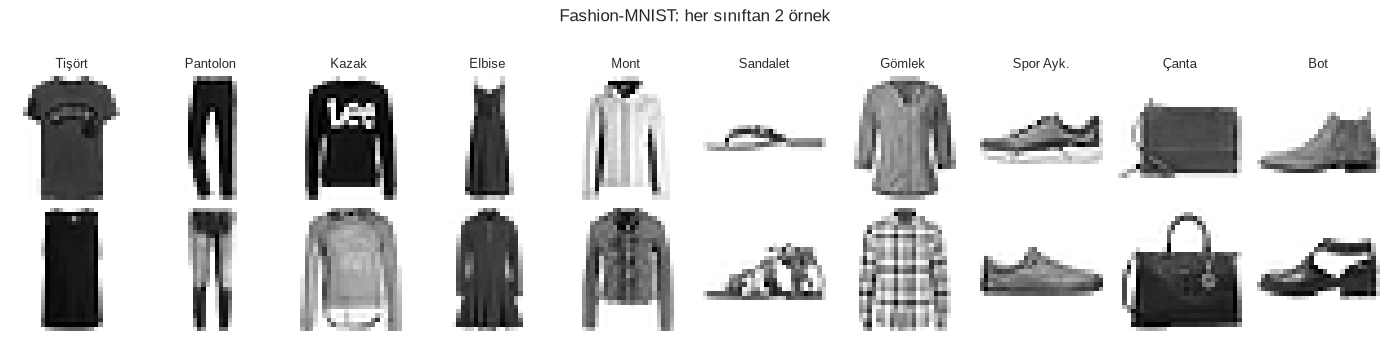

In [2]:
d = np.load('data/fashion_mnist_test.npz')
X_img, y_fm = d['X'].astype(np.float64) / 255.0, d['y']
class_names = ['Tişört', 'Pantolon', 'Kazak', 'Elbise', 'Mont', 'Sandalet', 'Gömlek', 'Spor Ayk.', 'Çanta', 'Bot']
print('Fashion-MNIST test:', X_img.shape, '| sınıf başına:', np.bincount(y_fm).tolist())
print('Piksel aralığı:', X_img.min(), '-', X_img.max(), '| sıfır piksel oranı: %.1f%%' % (100 * (X_img == 0).mean()))

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for c in range(10):
    idx = np.where(y_fm == c)[0][:2]
    for r, i in enumerate(idx):
        axes[r, c].imshow(X_img[i].reshape(28, 28), cmap='gray_r'); axes[r, c].axis('off')
    axes[0, c].set_title(class_names[c], fontsize=9)
plt.suptitle('Fashion-MNIST: her sınıftan 2 örnek', y=1.02); plt.tight_layout(); plt.show()

Sıfırdan vs sklearn PCA — maks. mutlak fark (işaret hizalı): 2.87e-13
Açıklanan varyans oranı farkı: 1.11e-16
%80 varyans için gereken bileşen sayısı: 24
%90 varyans için gereken bileşen sayısı: 83
%95 varyans için gereken bileşen sayısı: 183
%99 varyans için gereken bileşen sayısı: 446


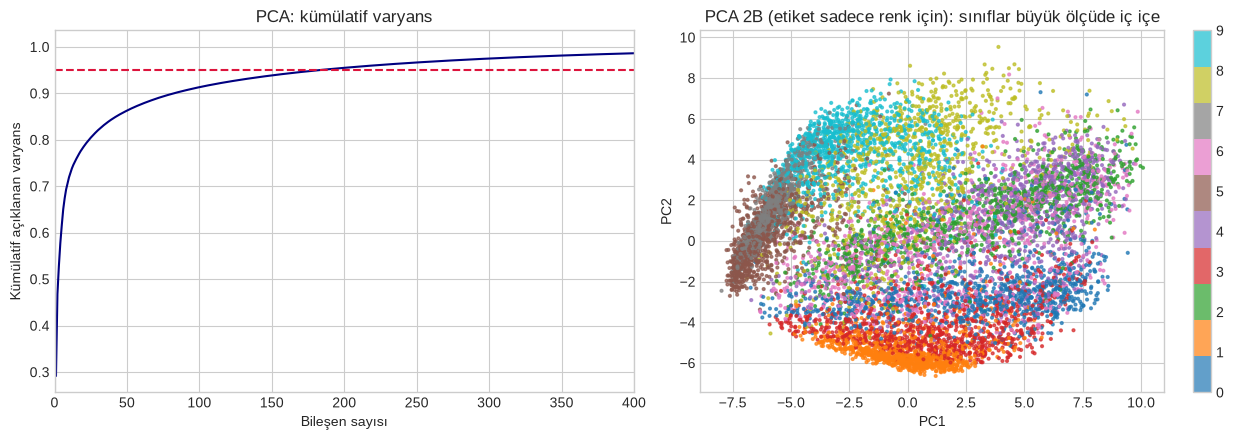

In [3]:
class SimplePCA:
    """SVD ile PCA (sıfırdan). X merkezlenir; Z = U_k * S_k."""
    def __init__(self, n_components):
        self.k = n_components
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        U, S, Vt = np.linalg.svd(X - self.mean_, full_matrices=False)
        self.components_ = Vt[:self.k]
        self.explained_variance_ = (S ** 2) / (len(X) - 1)
        self.evr_ = self.explained_variance_ / self.explained_variance_.sum()
        return self
    def transform(self, X):
        return (X - self.mean_) @ self.components_.T

my_pca = SimplePCA(50).fit(X_img)
sk_pca = PCA(n_components=50, svd_solver='full').fit(X_img)

Z_my, Z_sk = my_pca.transform(X_img), sk_pca.transform(X_img)
# işaret belirsizliği: her bileşeni sklearn ile aynı yöne çevir
sign = np.sign((Z_my * Z_sk).sum(axis=0))
print('Sıfırdan vs sklearn PCA — maks. mutlak fark (işaret hizalı): %.2e' % np.abs(Z_my * sign - Z_sk).max())
print('Açıklanan varyans oranı farkı: %.2e' % np.abs(my_pca.evr_[:50] - sk_pca.explained_variance_ratio_).max())

cum = np.cumsum(my_pca.evr_)
for thr in (0.80, 0.90, 0.95, 0.99):
    print(f'%{int(thr*100)} varyans için gereken bileşen sayısı: {np.searchsorted(cum, thr) + 1}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(1, 785), cum, color='navy'); axes[0].axhline(0.95, ls='--', color='crimson')
axes[0].set_xlim(0, 400); axes[0].set_xlabel('Bileşen sayısı'); axes[0].set_ylabel('Kümülatif açıklanan varyans'); axes[0].set_title('PCA: kümülatif varyans')
sc = axes[1].scatter(Z_sk[:, 0], Z_sk[:, 1], c=y_fm, cmap='tab10', s=4, alpha=0.7)
axes[1].set_title('PCA 2B (etiket sadece renk için): sınıflar büyük ölçüde iç içe')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2'); plt.colorbar(sc, ax=axes[1], ticks=range(10)); plt.tight_layout(); plt.show()

## Adım 2 · LDA: Elle Örnek, Sıfırdan Fisher LDA ve PCA→LDA Boru Hattı

**Ne yapıyoruz?** §3.3'teki 2 sınıflı, 2 öznitelikli örneği önce $\mathbf{S}_W^{-1}(\mathbf{m}_A-\mathbf{m}_B)$ ile elle (numpy) yeniden üretiyoruz.
Sonra **çok sınıflı** Fisher LDA'yı $\mathbf{S}_W^{-1}\mathbf{S}_B$'nin özayrışımı ile sıfırdan yazıyoruz ve `LinearDiscriminantAnalysis(solver='eigen')` ile karşılaştırıyoruz.

**784 piksel sorunu:** $\mathbf{S}_W$ ($784\times784$) birçok sabit/ölü piksel yüzünden **tekil** (tersi yok). Çözüm (Fisherfaces): önce PCA ile 50 boyuta in, sonra LDA.
LDA en fazla $C-1=9$ eksen verir; ilk iki eksen 2B harita olur.

In [4]:
# --- §3.3 elle örnek ---
A = np.array([[1, 2], [2, 3], [3, 3]], float); B = np.array([[3, 1], [4, 2], [5, 2]], float)
mA, mB = A.mean(0), B.mean(0)
Sw = (A - mA).T @ (A - mA) + (B - mB).T @ (B - mB)
w_fisher = np.linalg.solve(Sw, mA - mB)
print('m_A =', mA.round(3), '| m_B =', mB.round(3))
print('S_W =\n', Sw.round(3))
print('Fisher yönü w =', w_fisher.round(3), '| birim:', (w_fisher / np.linalg.norm(w_fisher)).round(3))
print('A izdüşümleri :', (A @ w_fisher).round(2), '| B izdüşümleri:', (B @ w_fisher).round(2))
print('Ortalamaları birleştiren yön (-2,1) ile Fisher yönü AYNI DEĞİL:', not np.allclose(w_fisher / np.linalg.norm(w_fisher), np.array([-2, 1]) / np.sqrt(5)))
lda2 = LinearDiscriminantAnalysis(solver='eigen').fit(np.vstack([A, B]), [0, 0, 0, 1, 1, 1])
cos = abs(lda2.scalings_[:, 0] @ w_fisher) / (np.linalg.norm(lda2.scalings_[:, 0]) * np.linalg.norm(w_fisher))
print('sklearn LDA yönü ile kosinüs benzerliği: %.6f (1 = aynı yön)' % cos)

m_A = [2.    2.667] | m_B = [4.    1.667]
S_W =
 [[4.    2.   ]
 [2.    1.333]]
Fisher yönü w = [-3.5  6. ] | birim: [-0.504  0.864]
A izdüşümleri : [ 8.5 11.   7.5] | B izdüşümleri: [-4.5 -2.  -5.5]
Ortalamaları birleştiren yön (-2,1) ile Fisher yönü AYNI DEĞİL: True
sklearn LDA yönü ile kosinüs benzerliği: 1.000000 (1 = aynı yön)


In [5]:
class SimpleLDA:
    """Çok sınıflı Fisher LDA (sıfırdan): S_W^{-1} S_B özayrışımı."""
    def __init__(self, n_components):
        self.k = n_components
    def fit(self, X, y):
        classes = np.unique(y); self.mean_ = X.mean(0); p = X.shape[1]
        Sw, Sb = np.zeros((p, p)), np.zeros((p, p))
        for c in classes:
            Xc = X[y == c]; mc = Xc.mean(0)
            Sw += (Xc - mc).T @ (Xc - mc)
            diff = (mc - self.mean_)[:, None]
            Sb += len(Xc) * diff @ diff.T
        vals, vecs = eigh(Sb, Sw)             # genelleştirilmiş özdeğer problemi: Sb v = λ Sw v
        order = np.argsort(vals)[::-1]
        self.eigvals_, self.W_ = vals[order], vecs[:, order[:self.k]]
        return self
    def transform(self, X):
        return (X - self.mean_) @ self.W_

# Fisherfaces: PCA(50) -> LDA(9)
pca50 = PCA(n_components=50, random_state=42).fit(X_img)
Z50 = pca50.transform(X_img)
Xtr, Xte, ytr, yte = train_test_split(Z50, y_fm, test_size=0.3, stratify=y_fm, random_state=42)

my_lda = SimpleLDA(9).fit(Xtr, ytr)
sk_lda = LinearDiscriminantAnalysis(solver='eigen', n_components=9).fit(Xtr, ytr)

print('En büyük 9 özdeğer (sıfırdan):', my_lda.eigvals_[:9].round(3))
print('sklearn explained_variance_ratio_ (ayrım payı):', sk_lda.explained_variance_ratio_.round(3))
# yön karşılaştırması: ilk 3 eksen için kosinüs benzerliği (işaret/ölçek farkından bağımsız)
for j in range(3):
    a, b = my_lda.W_[:, j], sk_lda.scalings_[:, j]
    print(f'LD{j+1}: kosinüs benzerliği = {abs(a @ b) / (np.linalg.norm(a) * np.linalg.norm(b)):.6f}')

Ztr_my, Zte_my = my_lda.transform(Xtr), my_lda.transform(Xte)
knn = KNeighborsClassifier(15).fit(Ztr_my, ytr)
print('\nSıfırdan LDA (9B) + kNN doğruluğu (test): %.4f' % knn.score(Zte_my, yte))
print('sklearn LDA sınıflandırıcı olarak (doğrudan)      : %.4f' % sk_lda.score(Xte, yte))
print('PCA(9B) + kNN (etiketsiz boyut indirgeme)         : %.4f' % KNeighborsClassifier(15).fit(Xtr[:, :9], ytr).score(Xte[:, :9], yte))

En büyük 9 özdeğer (sıfırdan): [11.486  4.974  2.085  1.719  1.562  1.079  0.742  0.325  0.123]
sklearn explained_variance_ratio_ (ayrım payı): [0.477 0.206 0.087 0.071 0.065 0.045 0.031 0.013 0.005]
LD1: kosinüs benzerliği = 1.000000
LD2: kosinüs benzerliği = 1.000000
LD3: kosinüs benzerliği = 1.000000

Sıfırdan LDA (9B) + kNN doğruluğu (test): 0.8040
sklearn LDA sınıflandırıcı olarak (doğrudan)      : 0.7807
PCA(9B) + kNN (etiketsiz boyut indirgeme)         : 0.7627


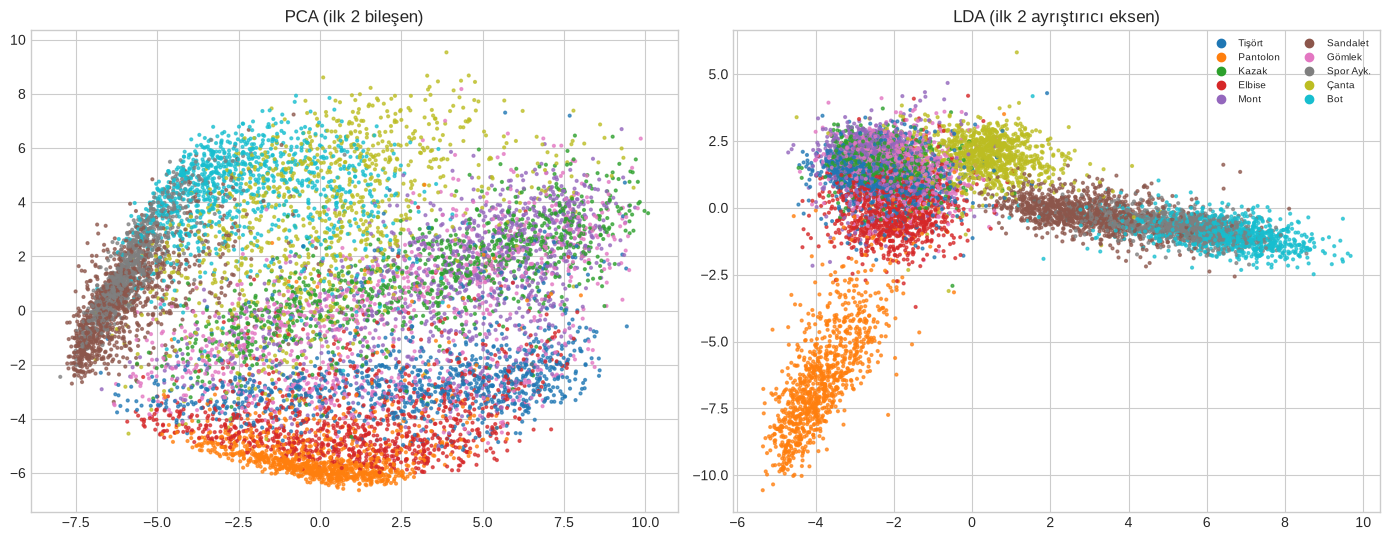

NOT: LDA etiketi kullandığı için sınıf ayrımı PCA'dan belirgin; ama bu "adil bir kıyas" değil — LDA'nın avantajı bilgi (etiket) farkıdır.


In [6]:
# PCA 2B ile LDA 2B'yi yan yana çiz (tüm 10.000 örnek, LDA PCA(50) üzerinde eğitilmiş)
lda_full = LinearDiscriminantAnalysis(solver='eigen', n_components=9).fit(Z50, y_fm)
Z_lda = lda_full.transform(Z50)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, Z, ttl in zip(axes, [Z50[:, :2], Z_lda[:, :2]], ['PCA (ilk 2 bileşen)', 'LDA (ilk 2 ayrıştırıcı eksen)']):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y_fm, cmap='tab10', s=4, alpha=0.7); ax.set_title(ttl)
axes[1].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=plt.cm.tab10(c / 9), label=class_names[c]) for c in range(10)],
               fontsize=7, ncol=2, loc='best')
plt.tight_layout(); plt.show()
print('NOT: LDA etiketi kullandığı için sınıf ayrımı PCA\'dan belirgin; ama bu "adil bir kıyas" değil — LDA\'nın avantajı bilgi (etiket) farkıdır.')

## Adım 3 · Kernel PCA: Elle Örnek, Sıfırdan Implementasyon ve $\gamma$ Duyarlılığı

**Ne yapıyoruz?** (1) §4.3'teki 3 noktalı örneği (kernel matrisi → merkezleme → özdeğer) elle yeniden üretiyoruz. (2) `SimpleKernelPCA` sınıfında
adımları (kernel, merkezleme, `eigh`, $\sqrt{\lambda}\,a$) yazıp `sklearn.KernelPCA` ile karşılaştırıyoruz; **yeni veri** için merkezlenmiş kernel satırını da kodluyoruz.
(3) İç içe iki halka (`make_circles`) üzerinde doğrusal PCA'nın neden başarısız olduğunu, Kernel PCA'nın ise sınıfları **doğrusal ayrılabilir** hale getirdiğini
lojistik regresyonun doğruluğuyla ölçüyoruz; $\gamma$ taramasıyla aşırı küçük/büyük değerlerin etkisini görüyoruz.

In [7]:
# --- §4.3 elle örnek ---
x3 = np.array([[0.], [1.], [3.]]); g = 0.5
K3 = rbf_kernel(x3, x3, gamma=g)
n3 = len(x3); J3 = np.eye(n3) - np.ones((n3, n3)) / n3
K3c = J3 @ K3 @ J3
lam3, a3 = np.linalg.eigh(K3c); order = np.argsort(lam3)[::-1]; lam3, a3 = lam3[order], a3[:, order]
print('K =\n', K3.round(4)); print('\nMerkezlenmiş K~ =\n', K3c.round(3))
print('\nÖzdeğerler:', lam3.round(4))
print('1. bileşen (sqrt(λ1)·a1):', (np.sqrt(lam3[0]) * a3[:, 0]).round(3), '(işaret keyfi)')
kp3 = KernelPCA(n_components=2, kernel='rbf', gamma=g).fit(x3)
print('sklearn KernelPCA 1. bileşen:', kp3.transform(x3)[:, 0].round(3))

K =
 [[1.     0.6065 0.0111]
 [0.6065 1.     0.1353]
 [0.0111 0.1353 1.    ]]

Merkezlenmiş K~ =
 [[ 0.422 -0.013 -0.41 ]
 [-0.013  0.339 -0.327]
 [-0.41  -0.327  0.736]]

Özdeğerler: [1.1117 0.3863 0.    ]
1. bileşen (sqrt(λ1)·a1): [-0.502 -0.354  0.857] (işaret keyfi)
sklearn KernelPCA 1. bileşen: [-0.502 -0.354  0.857]


In [8]:
class SimpleKernelPCA:
    """RBF Kernel PCA (sıfırdan). fit: K -> merkezle -> eigh. transform: merkezlenmiş kernel satırı."""
    def __init__(self, n_components, gamma):
        self.k, self.gamma = n_components, gamma
    def fit(self, X):
        self.X_ = X; n = len(X)
        K = rbf_kernel(X, X, gamma=self.gamma)
        self.K_col_mean_, self.K_all_mean_ = K.mean(axis=0), K.mean()
        J = np.eye(n) - np.ones((n, n)) / n
        Kc = J @ K @ J
        lam, A = np.linalg.eigh(Kc)
        order = np.argsort(lam)[::-1][:self.k]
        self.lam_, self.A_ = lam[order], A[:, order]
        return self
    def transform(self, X_new):
        Kn = rbf_kernel(X_new, self.X_, gamma=self.gamma)                 # (m, n)
        Kn_c = Kn - Kn.mean(axis=1, keepdims=True) - self.K_col_mean_ + self.K_all_mean_
        return Kn_c @ self.A_ / np.sqrt(self.lam_)

Xc, yc = make_circles(n_samples=1000, factor=0.3, noise=0.05, random_state=42)
my_kp = SimpleKernelPCA(2, gamma=3).fit(Xc)
sk_kp = KernelPCA(n_components=2, kernel='rbf', gamma=3).fit(Xc)
Zm, Zs = my_kp.transform(Xc), sk_kp.transform(Xc)
sgn = np.sign((Zm * Zs).sum(axis=0))
print('Sıfırdan vs sklearn KernelPCA — maks. fark (eğitim noktaları): %.2e' % np.abs(Zm * sgn - Zs).max())
# YENİ veri üzerinde (transform) doğrulama
Xnew, _ = make_circles(n_samples=200, factor=0.3, noise=0.05, random_state=7)
print('Yeni noktalar için maks. fark: %.2e' % np.abs(my_kp.transform(Xnew) * sgn - sk_kp.transform(Xnew)).max())

Sıfırdan vs sklearn KernelPCA — maks. fark (eğitim noktaları): 1.78e-14
Yeni noktalar için maks. fark: 1.68e-14


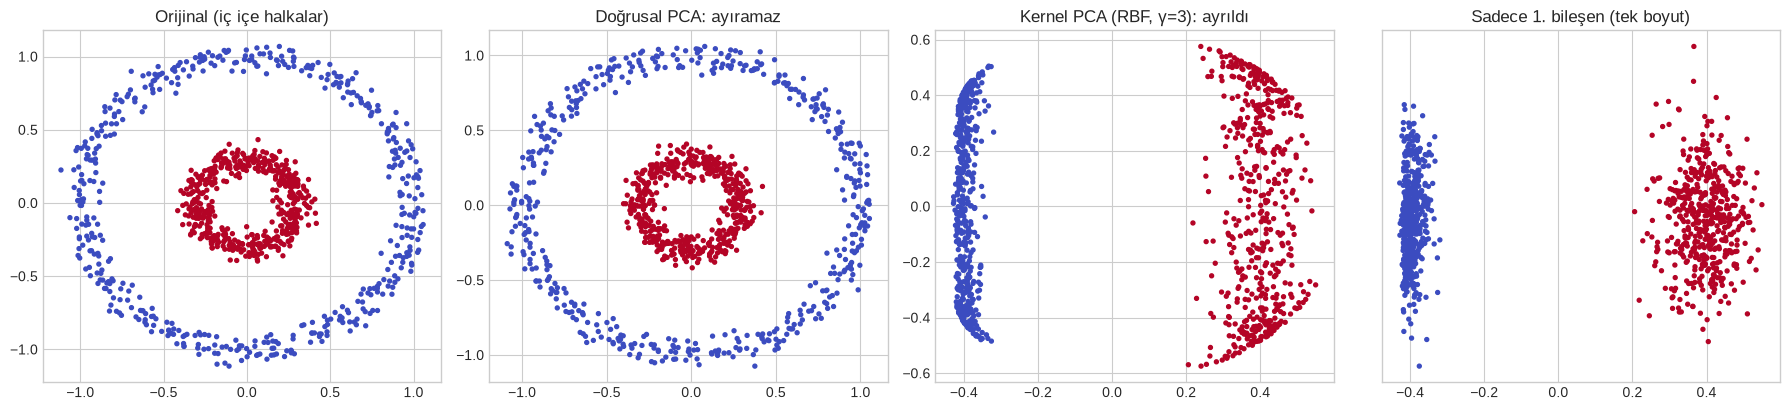

Doğrusal PCA(2B) + lojistik regresyon CV doğruluğu: 0.465


,gamma,"CV doğruluğu (LR, 2 bileşen)"
0,0.01,0.466
1,0.10,0.465
2,1.00,0.452
3,3.00,1.000
4,10.00,0.804
5,30.00,0.740
6,100.00,0.733
7,1000.00,0.594


YORUM: γ çok küçükken (≤1) kernel neredeyse doğrusal PCA gibi davranır ve halkaları ayıramaz; γ≈3'te iki halka 2 bileşenle TAM ayrılır (doğruluk 1.0);
       γ büyüdükçe (10 → 1000) kernel matrisi köşegene yaklaşır (her nokta kendi adası), bileşenler gürültüye döner ve doğruluk geri düşer.
       Yani γ "ne kadar büyük o kadar iyi" değil, veriye göre ayarlanması gereken dar bir pencere — çapraz doğrulama ile seçilmeli.


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap='coolwarm', s=8); axes[0].set_title('Orijinal (iç içe halkalar)')
Zp = PCA(2).fit_transform(Xc)
axes[1].scatter(Zp[:, 0], Zp[:, 1], c=yc, cmap='coolwarm', s=8); axes[1].set_title('Doğrusal PCA: ayıramaz')
axes[2].scatter(Zm[:, 0], Zm[:, 1], c=yc, cmap='coolwarm', s=8); axes[2].set_title('Kernel PCA (RBF, γ=3): ayrıldı')
axes[3].scatter(Zm[:, 0], np.zeros_like(Zm[:, 0]) + 0.02 * RNG.randn(len(Zm)), c=yc, cmap='coolwarm', s=8)
axes[3].set_title('Sadece 1. bileşen (tek boyut)'); axes[3].set_yticks([])
plt.tight_layout(); plt.show()

# doğrusal ayrılabilirliği lojistik regresyonla ölç + γ taraması
rows = []
for gam in [0.01, 0.1, 1, 3, 10, 30, 100, 1000]:
    Zg = KernelPCA(n_components=2, kernel='rbf', gamma=gam).fit_transform(Xc)
    acc = cross_val_score(LogisticRegression(), Zg, yc, cv=5).mean()
    rows.append((gam, acc))
print('Doğrusal PCA(2B) + lojistik regresyon CV doğruluğu: %.3f' % cross_val_score(LogisticRegression(), Zp, yc, cv=5).mean())
res = pd.DataFrame(rows, columns=['gamma', 'CV doğruluğu (LR, 2 bileşen)'])
display(res.round(3))
print('YORUM: γ çok küçükken (≤1) kernel neredeyse doğrusal PCA gibi davranır ve halkaları ayıramaz; γ≈3\'te iki halka 2 bileşenle TAM ayrılır (doğruluk 1.0);')
print('       γ büyüdükçe (10 → 1000) kernel matrisi köşegene yaklaşır (her nokta kendi adası), bileşenler gürültüye döner ve doğruluk geri düşer.')
print('       Yani γ "ne kadar büyük o kadar iyi" değil, veriye göre ayarlanması gereken dar bir pencere — çapraz doğrulama ile seçilmeli.')

In [10]:
# --- Gerçek veri: Fashion-MNIST alt kümesi (n=3000 — Kernel PCA O(n²) bellek/hesap) ---
sub = RNG.choice(len(X_img), 3000, replace=False)
Xs, ys = Z50[sub], y_fm[sub]                          # PCA(50) üzerinde çalış (gürültü azaltma)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, stratify=ys, random_state=42)

# γ için "medyan sezgisi": γ = 1 / (2 * medyan(uzaklık)^2)
med = np.median(pairwise_distances(Xs_tr[:500]))
gamma_med = 1 / (2 * med ** 2)
print(f'Medyan çiftli uzaklık = {med:.2f}  ->  γ (medyan sezgisi) = {gamma_med:.4f}')

res = []
for name, model in [('PCA(20)', PCA(20, random_state=42)),
                    ('KernelPCA RBF γ=medyan (20)', KernelPCA(20, kernel='rbf', gamma=gamma_med)),
                    ('KernelPCA RBF γ=10×medyan (20)', KernelPCA(20, kernel='rbf', gamma=10 * gamma_med)),
                    ('KernelPCA poly d=2 (20)', KernelPCA(20, kernel='poly', degree=2, gamma=gamma_med, coef0=1))]:
    t0 = time.time(); Ztr = model.fit_transform(Xs_tr); fit_t = time.time() - t0
    Zte = model.transform(Xs_te)
    acc = KNeighborsClassifier(15).fit(Ztr, ys_tr).score(Zte, ys_te)
    res.append((name, acc, fit_t))
display(pd.DataFrame(res, columns=['Yöntem', 'kNN test doğruluğu', 'fit süresi (sn)']).round(3))
print('Referans: ham PCA(50) üzerinde kNN = %.3f' % KNeighborsClassifier(15).fit(Xs_tr, ys_tr).score(Xs_te, ys_te))
print('YORUM: Fashion-MNIST gibi zaten büyük ölçüde "doğrusal ayrılabilir" öznitelik yapısında Kernel PCA PCA\'ya belirgin üstünlük sağlamayabilir;')
print('       üstünlük, asıl kıvrımlı/halkalı yapılarda (üstteki circles örneği) ortaya çıkar. Sonucu ölçüp karar vermek şart.')

Medyan çiftli uzaklık = 10.69  ->  γ (medyan sezgisi) = 0.0044


,Yöntem,kNN test doğruluğu,fit süresi (sn)
0,PCA(20),0.776,0.054
1,KernelPCA RBF γ=medyan (20),0.772,0.558
2,KernelPCA RBF γ=10×medyan (20),0.731,0.529
3,KernelPCA poly d=2 (20),0.766,0.539


Referans: ham PCA(50) üzerinde kNN = 0.778
YORUM: Fashion-MNIST gibi zaten büyük ölçüde "doğrusal ayrılabilir" öznitelik yapısında Kernel PCA PCA'ya belirgin üstünlük sağlamayabilir;
       üstünlük, asıl kıvrımlı/halkalı yapılarda (üstteki circles örneği) ortaya çıkar. Sonucu ölçüp karar vermek şart.


## Adım 4 · NMF: Elle Örnek, Sıfırdan Çarpımsal Güncelleme ve Olivetti Yüzlerinde "Parçalar"

**Ne yapıyoruz?** §5.3'teki $3\times2$ örneğin 3 turunu elle (numpy) çalıştırıp hatanın **monoton azaldığını** doğruluyoruz.
Sonra `SimpleNMF` sınıfında Lee & Seung çarpımsal kurallarını yazıp `sklearn.NMF(solver='mu')` ile aynı başlangıçtan karşılaştırıyoruz.
Son olarak **Olivetti Faces**'te (AT&T Laboratuvarı, 40 kişi × 10 poz, 64×64 gri; toplam 400 yüz) PCA'nın "eigenface"leri ile NMF'in
"parçalar"ını yan yana çiziyoruz — Lee & Seung (1999)'un ünlü deneyi.

In [11]:
# --- §5.3 elle örnek ---
V = np.array([[4, 2], [3, 1], [1, 3.]]); W = np.array([[1, 2], [2, 1], [1, 1.]]); H = np.array([[1, 1], [1, 2.]])
print('Başlangıç hatası ||V-WH||_F = %.3f' % np.linalg.norm(V - W @ H))
for it in range(1, 4):
    H = H * (W.T @ V) / (W.T @ W @ H)
    W = W * (V @ H.T) / (W @ H @ H.T)
    print(f'Tur {it}: hata = {np.linalg.norm(V - W @ H):.3f}')
    if it == 1:
        print('  H =\n', H.round(3), '\n  W =\n', W.round(3))
print('Tüm W,H elemanları >= 0 mı?', bool((W >= 0).all() and (H >= 0).all()))

Başlangıç hatası ||V-WH||_F = 4.472
Tur 1: hata = 2.143
  H =
 [[1.    0.438]
 [1.091 0.941]] 
  W =
 [[1.162 2.209]
 [1.769 0.829]
 [0.858 1.094]]
Tur 2: hata = 2.089
Tur 3: hata = 2.013
Tüm W,H elemanları >= 0 mı? True


In [12]:
class SimpleNMF:
    """Lee & Seung çarpımsal güncelleme (Frobenius). Tohum sabitlenebilir."""
    def __init__(self, n_components, n_iter=300, eps=1e-10, random_state=0):
        self.r, self.n_iter, self.eps, self.rs = n_components, n_iter, eps, random_state
    def fit(self, V, W0=None, H0=None):
        rs = np.random.RandomState(self.rs); n, p = V.shape
        avg = np.sqrt(V.mean() / self.r)
        W = W0.copy() if W0 is not None else avg * rs.rand(n, self.r)
        H = H0.copy() if H0 is not None else avg * rs.rand(self.r, p)
        self.errors_ = []
        for _ in range(self.n_iter):
            H *= (W.T @ V) / (W.T @ W @ H + self.eps)
            W *= (V @ H.T) / (W @ H @ H.T + self.eps)
            self.errors_.append(np.linalg.norm(V - W @ H))
        self.W_, self.H_ = W, H
        return self

# Olivetti
o = np.load('data/olivetti_faces.npz'); X_face, y_face = o['X'].astype(np.float64), o['y']
print('Olivetti:', X_face.shape, '| kişi sayısı:', len(np.unique(y_face)), '| aralık: %.2f-%.2f' % (X_face.min(), X_face.max()))

R = 25
my_nmf = SimpleNMF(R, n_iter=300, random_state=0).fit(X_face)
err_mono = np.all(np.diff(my_nmf.errors_) <= 1e-9)
print('Sıfırdan NMF: hata monoton azalıyor mu?', bool(err_mono), '| son hata: %.4f' % my_nmf.errors_[-1])

# sklearn: AYNI başlangıçtan (init='custom') çarpımsal güncelleme
rs0 = np.random.RandomState(0); avg = np.sqrt(X_face.mean() / R)
W0, H0 = avg * rs0.rand(*(X_face.shape[0], R)), avg * rs0.rand(R, X_face.shape[1])
sk_mu = NMF(R, init='custom', solver='mu', max_iter=300, tol=0).fit(X_face, W=W0.copy(), H=H0.copy())
print('sklearn NMF (solver=mu, aynı başlangıç) rekonstrüksiyon hatası: %.4f' % sk_mu.reconstruction_err_)
sk_nn = NMF(R, init='nndsvda', solver='cd', max_iter=2000, tol=1e-3, random_state=0).fit(X_face)
print('sklearn NMF (nndsvda+cd — akıllı başlangıç)  hatası          : %.4f  (daha iyi yerel çözüm)' % sk_nn.reconstruction_err_)

Olivetti: (400, 4096) | kişi sayısı: 40 | aralık: 0.00-1.00


Sıfırdan NMF: hata monoton azalıyor mu? True | son hata: 88.6372


sklearn NMF (solver=mu, aynı başlangıç) rekonstrüksiyon hatası: 88.6359


sklearn NMF (nndsvda+cd — akıllı başlangıç)  hatası          : 84.8681  (daha iyi yerel çözüm)


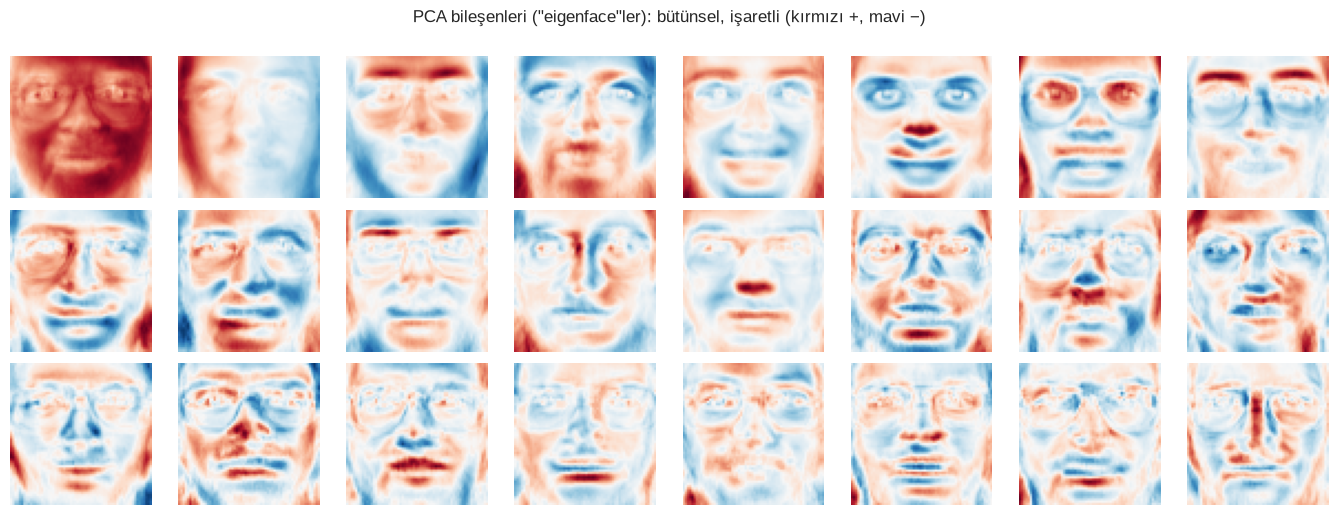

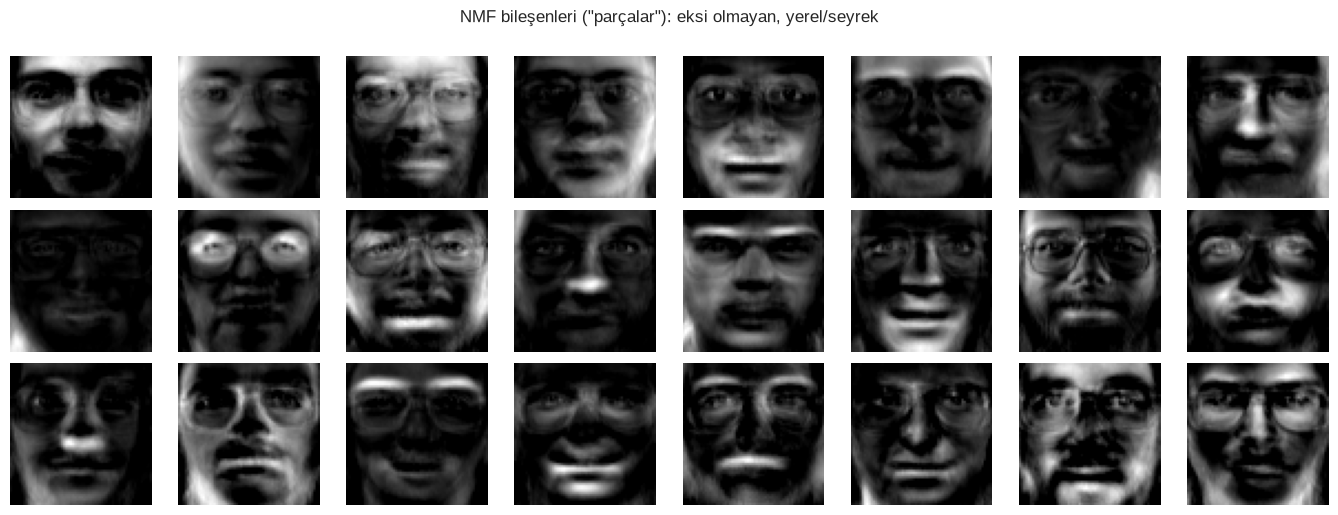

Bileşenlerin "neredeyse sıfır" piksel oranı — PCA: 0.032 | NMF: 0.238


In [13]:
def show_faces(comps, title, n_row=3, n_col=8, cmap='gray'):
    fig, axes = plt.subplots(n_row, n_col, figsize=(1.7 * n_col, 1.7 * n_row))
    for ax, c in zip(axes.ravel(), comps):
        vmax = np.abs(c).max()
        ax.imshow(c.reshape(64, 64), cmap=cmap, vmin=-vmax if cmap == 'RdBu_r' else None, vmax=vmax); ax.axis('off')
    plt.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

pca_face = PCA(24, whiten=False, random_state=42).fit(X_face)
show_faces(pca_face.components_, 'PCA bileşenleri ("eigenface"ler): bütünsel, işaretli (kırmızı +, mavi −)', cmap='RdBu_r')
show_faces(sk_nn.components_[:24], 'NMF bileşenleri ("parçalar"): eksi olmayan, yerel/seyrek')

def sparsity(M, thr=0.01):
    M = np.abs(M); return (M < thr * M.max(axis=1, keepdims=True)).mean()
print('Bileşenlerin "neredeyse sıfır" piksel oranı — PCA: %.3f | NMF: %.3f' % (sparsity(pca_face.components_), sparsity(sk_nn.components_)))

## Adım 5 · NMF ile Konu Modelleme (20 Newsgroups) ve LSA ile Karşılaştırma

**Ne yapıyoruz?** **20 Newsgroups** (Lang 1995; sklearn'ün dahili yükleyicisi) içinden birbirinden farklı **6 kategori** seçtik
(`sci.space`, `sci.med`, `rec.autos`, `rec.sport.hockey`, `comp.graphics`, `talk.politics.guns`; 5.604 yazı, başlık/imza/alıntılar çıkarılmış).
Tüm yazıları kullanıyoruz (örnek azaltılmadı). Belgeleri TF-IDF ile $\mathbf{V}$ (belge × kelime) matrisine çeviriyoruz.
`NMF(n_components=6)` ile 6 konu çıkarıp her konunun **en yüksek ağırlıklı kelimelerini** okuyoruz; sonra aynı veriye **LSA**
(`TruncatedSVD`, yani işaretli bileşenler) uygulayıp farkı görüyoruz. Etiketler öğrenmede **kullanılmıyor**; sadece sonda
"bulunan konular gerçek kategorilerle örtüşüyor mu?" diye bakıyoruz.

In [14]:
news = pd.read_csv('data/newsgroups_6cat.csv')
print('Belge sayısı:', len(news), '\n', news['target'].value_counts().to_string())

tfidf = TfidfVectorizer(stop_words='english', min_df=5, max_df=0.5, max_features=8000, token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
V_txt = tfidf.fit_transform(news['text'].fillna(''))
vocab = np.array(tfidf.get_feature_names_out())
print('\nTF-IDF matrisi:', V_txt.shape, '| yoğunluk: %.2f%%' % (100 * V_txt.nnz / np.prod(V_txt.shape)))

nmf_txt = NMF(n_components=6, init='nndsvda', max_iter=400, random_state=42)
W_txt = nmf_txt.fit_transform(V_txt); H_txt = nmf_txt.components_
print('NMF rekonstrüksiyon hatası: %.3f' % nmf_txt.reconstruction_err_)
print('\n=== NMF konuları (her konunun en yüksek 10 kelimesi) ===')
for t in range(6):
    print(f'Konu {t}:', ', '.join(vocab[np.argsort(H_txt[t])[::-1][:10]]))

Belge sayısı: 5604 
 target
rec.sport.hockey      960
sci.med               952
sci.space             948
comp.graphics         945
rec.autos             921
talk.politics.guns    878



TF-IDF matrisi: (5604, 8000) | yoğunluk: 0.62%


NMF rekonstrüksiyon hatası: 73.435

=== NMF konuları (her konunun en yüksek 10 kelimesi) ===
Konu 0: people, don, just, gun, think, like, right, know, guns, did
Konu 1: geb, shameful, dsl, chastity, cadre, skepticism, banks, intellect, pitt, surrender
Konu 2: game, hockey, team, games, espn, season, play, players, nhl, year
Konu 3: thanks, graphics, image, file, files, know, format, program, does, ftp
Konu 4: car, cars, engine, new, dealer, good, oil, ford, miles, like
Konu 5: space, nasa, shuttle, launch, orbit, earth, moon, mission, satellite, station


In [15]:
# Belge -> baskın konu; gerçek kategorilerle çapraz tablo
news['nmf_topic'] = W_txt.argmax(axis=1)
ct = pd.crosstab(news['target'], news['nmf_topic'])
display(ct)
purity = ct.max(axis=0).sum() / ct.values.sum()
print('Konu saflığı (purity): %.3f' % purity)
print('YORUM: Etiket kullanılmadan 4 kategori (grafik, otomobil, hokey, uzay) temiz konular olarak bulundu. Ama (1) Konu 0, "silah" ile "tıp" yazılarını')
print('       genel tartışma dili (people, don, just, think...) etrafında birleştirdi; (2) Konu 1 bir ARTEFAKT: tek bir yazarın e-posta imzasından')
print('       (geb, shameful, chastity, skepticism... "Pitt" imzası) çıkan bir "konu". Gerçek projede bu, ön işleme (imza/ortak ifade temizliği) veya')
print('       daha fazla konu gerektiğinin işaretidir — E3\'te konu sayısını 10\'a çıkararak bu davranışı inceleyeceksin.')

# LSA (SVD) karşılaştırması: bileşenler işaretli
lsa = TruncatedSVD(n_components=6, random_state=42).fit(V_txt)
print('\n=== LSA (TruncatedSVD) bileşenleri: + ve − uçları ===')
for t in range(3):
    order = np.argsort(lsa.components_[t])
    print(f'Bileşen {t}:  (+) ' + ', '.join(vocab[order[::-1][:8]]) + '\n             (−) ' + ', '.join(vocab[order[:8]]))
print('\nLSA bileşenlerinde negatif ağırlıklar var -> "konu" doğrudan okunamaz (ör. bileşen 1: bir konuya karşı diğeri).')
print('NMF\'de tüm ağırlıklar >= 0: her konu "bir kelime torbası"; belgenin konu karışımı da >= 0 (W satırı).')
print('Bir belgenin NMF konu karışımı (ilk belge):', W_txt[0].round(3), '| toplamı normalize edilince:', (W_txt[0] / W_txt[0].sum()).round(2))

nmf_topic,0,1,2,3,4,5
target,,,,,,
comp.graphics,96,5,7,789,10,38
rec.autos,155,4,2,53,697,10
rec.sport.hockey,83,6,835,24,8,4
sci.med,673,87,7,133,17,35
sci.space,207,3,10,61,27,640
talk.politics.guns,820,6,6,20,13,13


Konu saflığı (purity): 0.690
YORUM: Etiket kullanılmadan 4 kategori (grafik, otomobil, hokey, uzay) temiz konular olarak bulundu. Ama (1) Konu 0, "silah" ile "tıp" yazılarını
       genel tartışma dili (people, don, just, think...) etrafında birleştirdi; (2) Konu 1 bir ARTEFAKT: tek bir yazarın e-posta imzasından
       (geb, shameful, chastity, skepticism... "Pitt" imzası) çıkan bir "konu". Gerçek projede bu, ön işleme (imza/ortak ifade temizliği) veya
       daha fazla konu gerektiğinin işaretidir — E3'te konu sayısını 10'a çıkararak bu davranışı inceleyeceksin.

=== LSA (TruncatedSVD) bileşenleri: + ve − uçları ===
Bileşen 0:  (+) don, like, just, know, people, think, good, car
             (−) hobbes, gilbert, uploads, taglianetti, lefebvre, subsampling, maurice, daniels
Bileşen 1:  (+) geb, shameful, dsl, chastity, cadre, skepticism, banks, intellect
             (−) game, team, hockey, games, espn, play, season, players
Bileşen 2:  (+) game, hockey, team, games, espn, play, seaso

## Adım 6 · ICA: Kurtosis, Merkezi Limit Teoremi ve Sıfırdan FastICA (Kokteyl Partisi)

**Ne yapıyoruz?** (1) §6.3'teki iddiayı simülasyonla doğruluyoruz: iki bağımsız $\text{Uniform}(-1,1)$ kaynağın karışımı daha Gauss'a yakın (kurtosis 0'a yaklaşır).
(2) Üç bağımsız kaynaktan (sinüs, kare dalga, testere dişi) 3 mikrofon karışımı üretip **sıfırdan FastICA** yazıyoruz: merkezle → beyazlat →
`tanh` sabit-nokta iterasyonu + Gram-Schmidt (deflation). (3) Sonucu `sklearn.FastICA` ve **PCA** ile karşılaştırıyoruz;
kaynak kurtarma başarısını gerçek kaynaklarla **korelasyon matrisinden** okuyoruz (ICA sıra/işaret belirsizliği yüzünden mutlak korelasyon).

In [16]:
# --- §6.3: karışım Gauss'a yaklaşır ---
rs = np.random.RandomState(0); N = 200_000
s1, s2, s3, s4 = (rs.uniform(-1, 1, N) for _ in range(4))
print('Uniform kaynak                : fazla basıklık = %+.3f  (teorik -1.200)' % kurtosis(s1))
print('2 kaynağın karışımı (s1+s2)/√2: fazla basıklık = %+.3f  (teorik -0.600)' % kurtosis((s1 + s2) / np.sqrt(2)))
print('4 kaynağın karışımı           : fazla basıklık = %+.3f  (teorik -0.300)' % kurtosis((s1 + s2 + s3 + s4) / 2))
print('Gauss                         : fazla basıklık = %+.3f  (teorik  0.000)' % kurtosis(rs.randn(N)))
print('Laplace (süper-Gauss)         : fazla basıklık = %+.3f  (teorik +3.000)' % kurtosis(rs.laplace(size=N)))

# --- Kokteyl partisi ---
from scipy import signal
n = 4000; t = np.linspace(0, 8, n)
S_true = np.c_[np.sin(2 * t), np.sign(np.sin(3 * t)), signal.sawtooth(2 * np.pi * t)]
S_true += 0.02 * rs.randn(*S_true.shape)
S_true /= S_true.std(axis=0)
A_mix = np.array([[1.0, 1.0, 1.0], [0.5, 2.0, 1.0], [1.5, 1.0, 2.0]])
X_mix = S_true @ A_mix.T
print('\nKaynak:', S_true.shape, '| Karışım matrisi A:\n', A_mix)
print('Kaynakların fazla basıklığı :', kurtosis(S_true).round(2))
print('Karışımların fazla basıklığı:', kurtosis(X_mix).round(2), ' (Gauss\'a yakın, mutlak değerce daha küçük)')

Uniform kaynak                : fazla basıklık = -1.202  (teorik -1.200)
2 kaynağın karışımı (s1+s2)/√2: fazla basıklık = -0.604  (teorik -0.600)
4 kaynağın karışımı           : fazla basıklık = -0.304  (teorik -0.300)
Gauss                         : fazla basıklık = +0.002  (teorik  0.000)
Laplace (süper-Gauss)         : fazla basıklık = +2.902  (teorik +3.000)



Kaynak: (4000, 3) | Karışım matrisi A:
 [[1.  1.  1. ]
 [0.5 2.  1. ]
 [1.5 1.  2. ]]
Kaynakların fazla basıklığı : [-1.36 -1.99 -1.2 ]
Karışımların fazla basıklığı: [-0.49 -1.19 -0.42]  (Gauss'a yakın, mutlak değerce daha küçük)


In [17]:
class SimpleFastICA:
    """FastICA (sıfırdan): merkezle -> beyazlat -> deflation + tanh sabit nokta."""
    def __init__(self, n_components, max_iter=500, tol=1e-6, random_state=0):
        self.k, self.max_iter, self.tol, self.rs = n_components, max_iter, tol, random_state
    def fit_transform(self, X):
        rs = np.random.RandomState(self.rs); n, p = X.shape
        self.mean_ = X.mean(0); Xc = X - self.mean_
        lam, E = np.linalg.eigh(np.cov(Xc.T))                       # beyazlatma
        idx = np.argsort(lam)[::-1][:self.k]
        self.whiten_ = (E[:, idx] / np.sqrt(lam[idx])).T            # (k, p)
        Z = Xc @ self.whiten_.T                                     # (n, k), kovaryans = I
        W = np.zeros((self.k, self.k)); self.n_iter_ = []
        for i in range(self.k):
            w = rs.randn(self.k); w /= np.linalg.norm(w)
            for it in range(self.max_iter):
                wz = Z @ w
                g, gp = np.tanh(wz), 1 - np.tanh(wz) ** 2
                w_new = (Z * g[:, None]).mean(0) - gp.mean() * w     # E[z g(w'z)] - E[g'(w'z)] w
                w_new -= W[:i].T @ (W[:i] @ w_new)                   # Gram-Schmidt
                w_new /= np.linalg.norm(w_new)
                done = abs(abs(w_new @ w) - 1) < self.tol
                w = w_new
                if done: break
            self.n_iter_.append(it + 1); W[i] = w
        self.W_ = W
        self.unmixing_ = W @ self.whiten_                           # S = (X - mean) @ unmixing_.T
        return Z @ W.T
    def transform(self, X):
        return (X - self.mean_) @ self.unmixing_.T

my_ica = SimpleFastICA(3, random_state=0); S_my = my_ica.fit_transform(X_mix)
sk_ica = FastICA(n_components=3, whiten='unit-variance', random_state=0, max_iter=1000, tol=1e-6); S_sk = sk_ica.fit_transform(X_mix)
S_pca = PCA(3, whiten=True).fit_transform(X_mix)

def best_abs_corr(S_est, S_ref):
    C = np.abs(np.corrcoef(S_est.T, S_ref.T)[:3, 3:])      # (est x true)
    return C, C.max(axis=1)

for name, S_est in [('Sıfırdan FastICA', S_my), ('sklearn FastICA', S_sk), ('PCA (beyazlatılmış)', S_pca)]:
    C, m = best_abs_corr(S_est, S_true)
    print(f'{name:22s}: her bileşenin en iyi eşleştiği kaynakla |korelasyon| =', m.round(3), '| ort. = %.3f' % m.mean())
print('Sıfırdan FastICA iterasyon sayıları:', my_ica.n_iter_)
C, _ = best_abs_corr(S_my, S_true); print('\nSıfırdan ICA |korelasyon| matrisi (satır: bulunan bileşen, sütun: gerçek kaynak):\n', C.round(3))

Sıfırdan FastICA      : her bileşenin en iyi eşleştiği kaynakla |korelasyon| = [1.    0.998 0.996] | ort. = 0.998
sklearn FastICA       : her bileşenin en iyi eşleştiği kaynakla |korelasyon| = [0.997 0.997 0.999] | ort. = 0.998
PCA (beyazlatılmış)   : her bileşenin en iyi eşleştiği kaynakla |korelasyon| = [0.61  0.783 0.753] | ort. = 0.715
Sıfırdan FastICA iterasyon sayıları: [4, 3, 2]

Sıfırdan ICA |korelasyon| matrisi (satır: bulunan bileşen, sütun: gerçek kaynak):
 [[0.086 1.    0.055]
 [0.014 0.    0.998]
 [0.996 0.    0.003]]


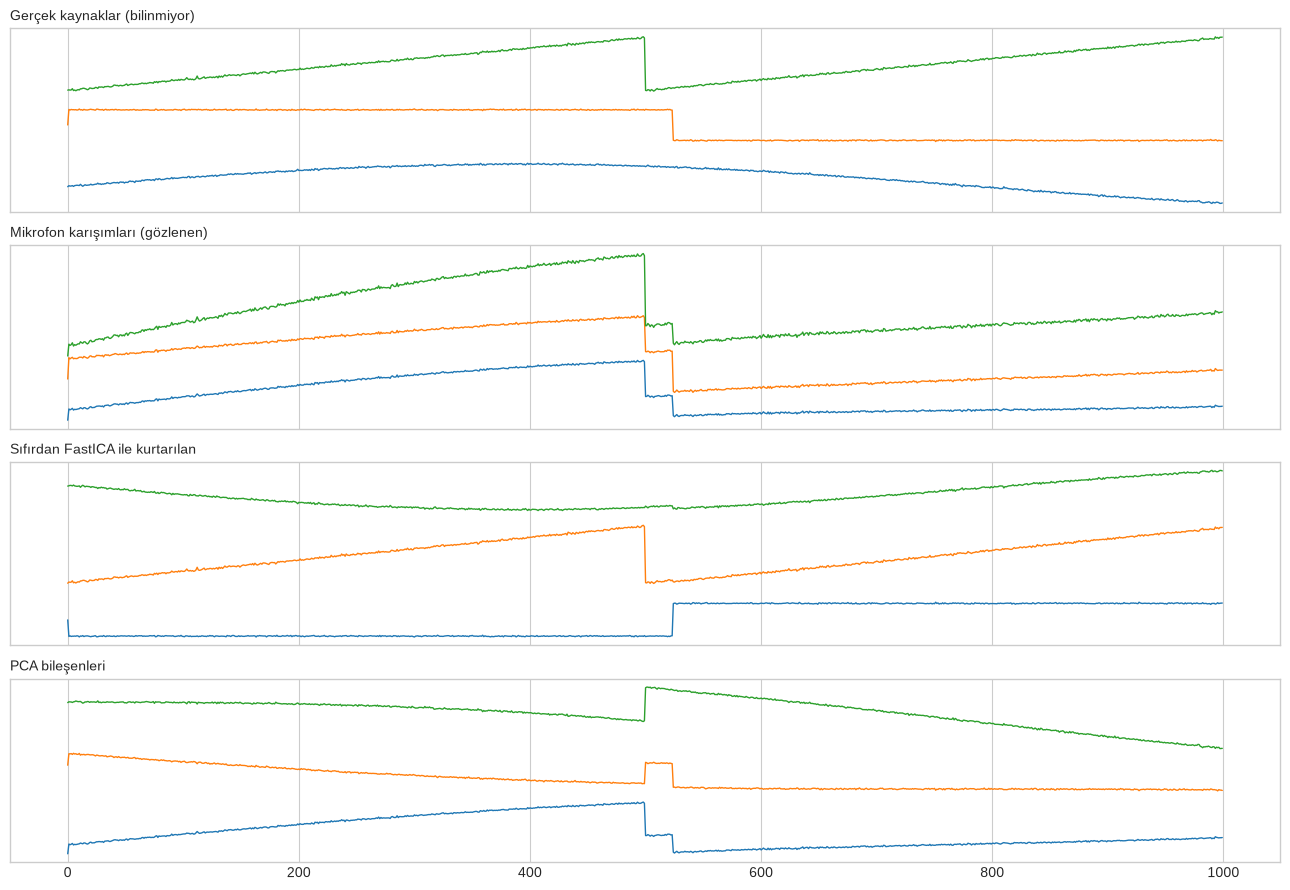

YORUM: ICA kaynak şekillerini (sinüs, kare dalga, testere) sıra ve işaret hariç geri getirdi; PCA ilintisiz ama hâlâ KARIŞIK bileşenler verdi.
       İşaret/sıra belirsizliği ICA'nın doğasında: korelasyonun mutlak değerini aldık.


In [18]:
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
sl = slice(0, 1000)
for ax, (M, ttl) in zip(axes, [(S_true, 'Gerçek kaynaklar (bilinmiyor)'), (X_mix, 'Mikrofon karışımları (gözlenen)'),
                               (S_my, 'Sıfırdan FastICA ile kurtarılan'), (S_pca, 'PCA bileşenleri')]):
    for j in range(3): ax.plot(M[sl, j] + 4 * j, lw=1)
    ax.set_title(ttl, loc='left', fontsize=10); ax.set_yticks([])
plt.tight_layout(); plt.show()
print('YORUM: ICA kaynak şekillerini (sinüs, kare dalga, testere) sıra ve işaret hariç geri getirdi; PCA ilintisiz ama hâlâ KARIŞIK bileşenler verdi.')
print('       İşaret/sıra belirsizliği ICA\'nın doğasında: korelasyonun mutlak değerini aldık.')

## Adım 7 · Yüz Verisinde PCA / NMF / ICA Yan Yana: Bileşenlerin "Karakteri"

**Ne yapıyoruz?** Aynı Olivetti verisinde üç yöntemin bileşenlerini yan yana koyuyor ve **kurtosis** (sivrilik: yerel/seyrek yapılar yüksek pozitif kurtosis verir)
ile niceliksel olarak karşılaştırıyoruz. ICA'yı yüzlerde **Bartlett ve ark. (2002) "mimari I"** ile uyguluyoruz: önce PCA(24) ile gürültüyü süpürüp
PCA bileşenlerinin ($24\times4096$) *piksel konumlarını örnek* sayarak ICA yapıyoruz; çıkan her bileşen bağımsız bir **piksel haritası** olur.

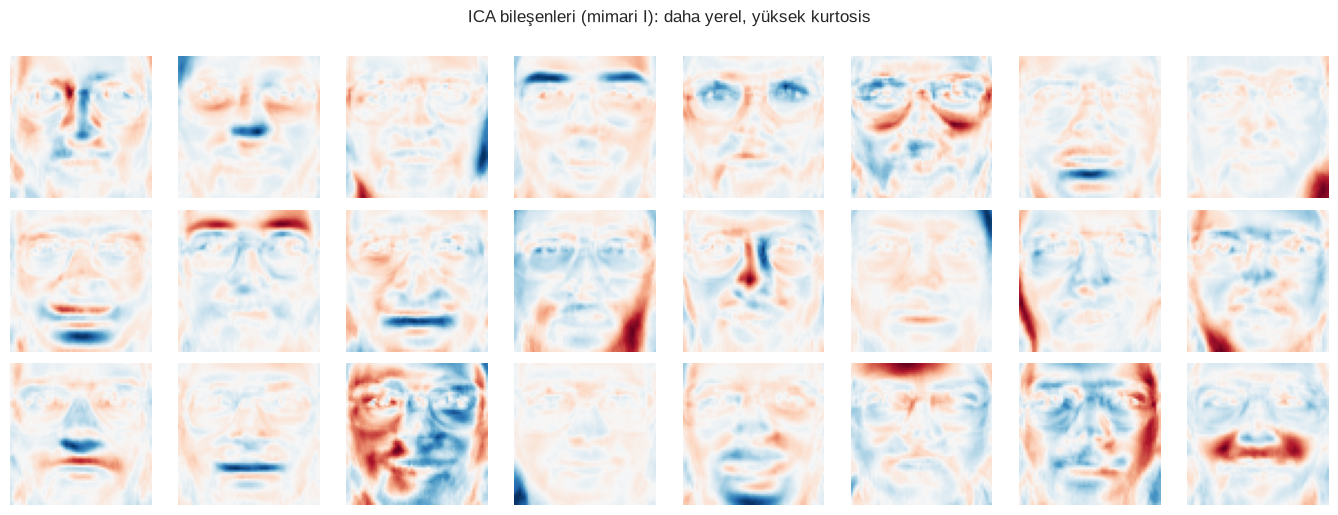

,Yöntem,Ortalama fazla basıklık (bileşen piksel dağılımı)
0,PCA,0.71
1,NMF,2.93
2,ICA,7.74


YORUM: Yüksek basıklık = piksel ağırlıkları az sayıda pikselde yoğunlaşıyor (yerel, seyrek bileşen). PCA bütünsel (düşük basıklık);
       NMF ve ICA daha yerel parçalar üretiyor — ama NMF'in avantajı, parçaların ve katsayıların >= 0 olması (toplamsal yorum).


In [19]:
pca24 = PCA(24, random_state=42).fit(X_face)
P_comp = pca24.components_                                        # (24, 4096)
ica_f = FastICA(n_components=24, whiten='unit-variance', random_state=0, max_iter=2000, tol=1e-5)
S_pix = ica_f.fit_transform(P_comp.T)                             # (4096 piksel, 24) -> her sütun bir "bağımsız görüntü"
ICA_comp = S_pix.T                                                # (24, 4096)

show_faces(ICA_comp, 'ICA bileşenleri (mimari I): daha yerel, yüksek kurtosis', cmap='RdBu_r')
nmf24 = NMF(24, init='nndsvda', max_iter=2000, tol=1e-3, random_state=0).fit(X_face)

kurt = pd.DataFrame({'Yöntem': ['PCA', 'NMF', 'ICA'],
                     'Ortalama fazla basıklık (bileşen piksel dağılımı)': [kurtosis(P_comp, axis=1).mean(), kurtosis(nmf24.components_, axis=1).mean(), kurtosis(ICA_comp, axis=1).mean()]})
display(kurt.round(2))
print('YORUM: Yüksek basıklık = piksel ağırlıkları az sayıda pikselde yoğunlaşıyor (yerel, seyrek bileşen). PCA bütünsel (düşük basıklık);')
print('       NMF ve ICA daha yerel parçalar üretiyor — ama NMF\'in avantajı, parçaların ve katsayıların >= 0 olması (toplamsal yorum).')

## Adım 8 · t-SNE: Elle Örnek, Sıfırdan (Kesin) t-SNE, `sklearn.TSNE` ve Yorum Tuzakları

**Ne yapıyoruz?** (1) §7.3'teki 3 noktalı örneğin $p_{j|i}$ ve simetrik $p_{ij}$ tablolarını yeniden üretiyoruz ve perplexity'nin $\sigma$'yı nasıl belirlediğini
ikili aramayla gösteriyoruz. (2) 600 Fashion-MNIST örneği üzerinde **kesin (O(n²)) t-SNE'yi sıfırdan** yazıyoruz: $\sigma$ araması → $P$ → Student-t $Q$ → gradyan
(momentumlu) ve early exaggeration; KL kaybının düştüğünü ve `sklearn.TSNE` ile benzer *trustworthiness* verdiğini doğruluyoruz. (3) Tam 10.000 örnekte
`sklearn.TSNE` (PCA(50) girişi, `init='pca'`) çalıştırıyoruz. (4) Perplexity duyarlılığını ve §7.4'teki **yorum tuzaklarını** (küme boyutu/uzaklığı anlamsız) deneysel gösteriyoruz.

In [20]:
# --- §7.3 elle örnek: 3 nokta ---
x1 = np.array([0., 1., 5.]); D2 = (x1[:, None] - x1[None, :]) ** 2
Pc = np.exp(-D2 / 2.0); np.fill_diagonal(Pc, 0); Pc /= Pc.sum(1, keepdims=True)           # p_{j|i}, σ=1
Pj = (Pc + Pc.T) / (2 * 3)
print('p_{j|i} (satır i, sütun j), σ=1:\n', Pc.round(4)); print('\nSimetrik p_ij:\n', Pj.round(4), '| toplam =', Pj.sum().round(6))

# perplexity -> σ (ikili arama): nokta 1 (ortadaki) için 2 etkin komşu isteyelim
def perplexity_of(d2, sigma):
    p = np.exp(-d2 / (2 * sigma ** 2)); p /= p.sum()
    return 2 ** (-(p[p > 0] * np.log2(p[p > 0])).sum())
d2_pt1 = np.array([1.0, 16.0])                    # nokta 1'in diğer iki noktaya kare uzaklığı (0 ve 5)
for sg in [0.5, 1, 2, 4, 8]:
    print(f'σ={sg:>3}: perplexity = {perplexity_of(d2_pt1, sg):.3f}')
sig_star = brentq(lambda s: perplexity_of(d2_pt1, s) - 1.5, 0.3, 50)
print(f'Perplexity=1.5 hedefi için σ* = {sig_star:.3f}  (perplexity ≈ "etkin komşu sayısı"; σ büyüdükçe 2\'ye yaklaşır)')

p_{j|i} (satır i, sütun j), σ=1:
 [[0.000e+00 1.000e+00 0.000e+00]
 [9.994e-01 0.000e+00 6.000e-04]
 [1.100e-02 9.890e-01 0.000e+00]]

Simetrik p_ij:
 [[0.     0.3332 0.0018]
 [0.3332 0.     0.1649]
 [0.0018 0.1649 0.    ]] | toplam = 1.0
σ=0.5: perplexity = 1.000
σ=  1: perplexity = 1.005
σ=  2: perplexity = 1.480
σ=  4: perplexity = 1.947
σ=  8: perplexity = 1.997
Perplexity=1.5 hedefi için σ* = 2.034  (perplexity ≈ "etkin komşu sayısı"; σ büyüdükçe 2'ye yaklaşır)


Sıfırdan t-SNE süresi: 4.6 sn
KL (başlangıç -> son): 3.23 -> 0.616


Trustworthiness(k=10) — sıfırdan: 0.9797 | sklearn(exact): 0.9868
KL — sıfırdan (exaggeration sonrası): 0.616 | sklearn kl_divergence_: 0.518


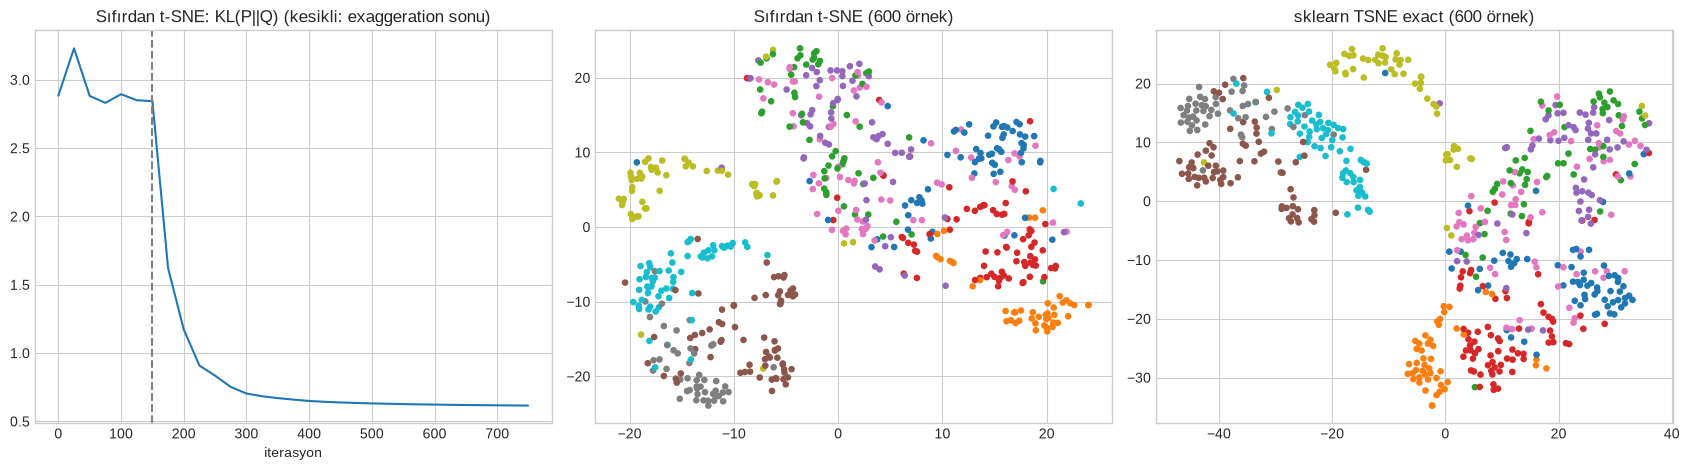

In [21]:
class SimpleTSNE:
    """Kesin (exact) t-SNE, sıfırdan. PCA başlangıcı, early exaggeration, momentum."""
    def __init__(self, perplexity=30, n_iter=750, lr=200., exag=12., exag_iter=150, random_state=42):
        self.perp, self.n_iter, self.lr, self.exag, self.exag_iter, self.rs = perplexity, n_iter, lr, exag, exag_iter, random_state
    def _joint_p(self, X):
        n = len(X); D2 = pairwise_distances(X, squared=True); P = np.zeros((n, n)); target = np.log(self.perp)
        for i in range(n):
            d = np.delete(D2[i], i)
            lo, hi, beta = 1e-20, 1e20, 1.0                       # beta = 1/(2σ²)
            for _ in range(60):
                p = np.exp(-(d - d.min()) * beta); sp = p.sum(); p /= sp
                H = -(p[p > 0] * np.log(p[p > 0])).sum()
                if abs(H - target) < 1e-5: break
                if H > target: lo = beta; beta = beta * 2 if hi >= 1e19 else (beta + hi) / 2
                else: hi = beta; beta = beta / 2 if lo <= 1e-19 else (beta + lo) / 2
            P[i, np.arange(n) != i] = p
        P = (P + P.T) / (2 * n)
        return np.maximum(P, 1e-12)
    def fit_transform(self, X):
        P = self._joint_p(X); n = len(X)
        Y = PCA(2, random_state=self.rs).fit_transform(X); Y = 1e-4 * Y / Y[:, 0].std()
        vel = np.zeros_like(Y); self.kl_ = []
        for it in range(self.n_iter):
            Pe = P * (self.exag if it < self.exag_iter else 1.0)
            num = 1.0 / (1.0 + pairwise_distances(Y, squared=True)); np.fill_diagonal(num, 0)
            Q = np.maximum(num / num.sum(), 1e-12)
            PQ = (Pe - Q) * num
            grad = 4 * (np.diag(PQ.sum(1)) - PQ) @ Y
            mom = 0.5 if it < 250 else 0.8
            vel = mom * vel - self.lr * grad; Y = Y + vel; Y -= Y.mean(0)
            if it % 25 == 0 or it == self.n_iter - 1:
                self.kl_.append((it, (P * np.log(P / Q)).sum()))
        self.embedding_ = Y
        return Y

sub600 = RNG.choice(len(X_img), 600, replace=False)
X600, y600 = Z50[sub600], y_fm[sub600]
t0 = time.time(); my_tsne = SimpleTSNE(perplexity=30, n_iter=750); Y_my = my_tsne.fit_transform(X600); t_my = time.time() - t0
print('Sıfırdan t-SNE süresi: %.1f sn' % t_my)
kl = np.array(my_tsne.kl_); print('KL (başlangıç -> son):', kl[1, 1].round(3), '->', kl[-1, 1].round(3))

sk_t600 = TSNE(2, perplexity=30, init='pca', learning_rate='auto', method='exact', random_state=42).fit(X600)
print('Trustworthiness(k=10) — sıfırdan: %.4f | sklearn(exact): %.4f' % (trustworthiness(X600, Y_my, n_neighbors=10), trustworthiness(X600, sk_t600.embedding_, n_neighbors=10)))
print('KL — sıfırdan (exaggeration sonrası): %.3f | sklearn kl_divergence_: %.3f' % (kl[-1, 1], sk_t600.kl_divergence_))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].plot(kl[:, 0], kl[:, 1]); axes[0].axvline(150, ls='--', color='gray'); axes[0].set_title('Sıfırdan t-SNE: KL(P||Q) (kesikli: exaggeration sonu)'); axes[0].set_xlabel('iterasyon')
for ax, Y, ttl in zip(axes[1:], [Y_my, sk_t600.embedding_], ['Sıfırdan t-SNE (600 örnek)', 'sklearn TSNE exact (600 örnek)']):
    ax.scatter(Y[:, 0], Y[:, 1], c=y600, cmap='tab10', s=14); ax.set_title(ttl)
plt.tight_layout(); plt.show()

t-SNE (n=10.000, Barnes-Hut): 47 sn | KL = 1.498


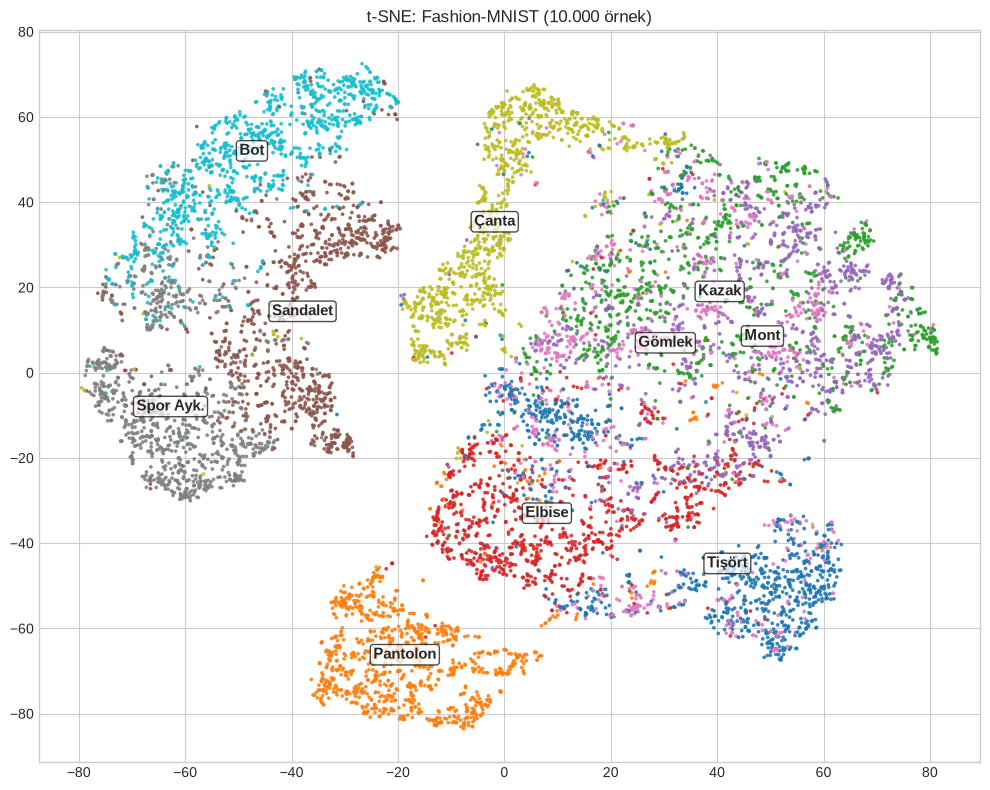

YORUM: Ayakkabı grubu (Sandalet/Spor Ayk./Bot) ve üst giyim (Tişört/Gömlek/Kazak/Mont) bölgeleri belirgin; Gömlek hem Tişört hem Kazak ile iç içe — zor sınıf.


In [22]:
# --- Tam 10.000 örnek: sklearn TSNE (Barnes-Hut), PCA(50) girişi ---
t0 = time.time()
tsne_full = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=42, n_jobs=2)
Y_tsne = tsne_full.fit_transform(Z50); T_tsne = time.time() - t0
print('t-SNE (n=10.000, Barnes-Hut): %.0f sn | KL = %.3f' % (T_tsne, tsne_full.kl_divergence_))

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(Y_tsne[:, 0], Y_tsne[:, 1], c=y_fm, cmap='tab10', s=3, alpha=0.8)
for c in range(10):
    cx, cy = np.median(Y_tsne[y_fm == c], axis=0); ax.text(cx, cy, class_names[c], fontsize=11, weight='bold', ha='center',
                                                          bbox=dict(facecolor='white', alpha=0.7, boxstyle='round,pad=0.2'))
ax.set_title('t-SNE: Fashion-MNIST (10.000 örnek)'); plt.tight_layout(); plt.show()
print('YORUM: Ayakkabı grubu (Sandalet/Spor Ayk./Bot) ve üst giyim (Tişört/Gömlek/Kazak/Mont) bölgeleri belirgin; Gömlek hem Tişört hem Kazak ile iç içe — zor sınıf.')

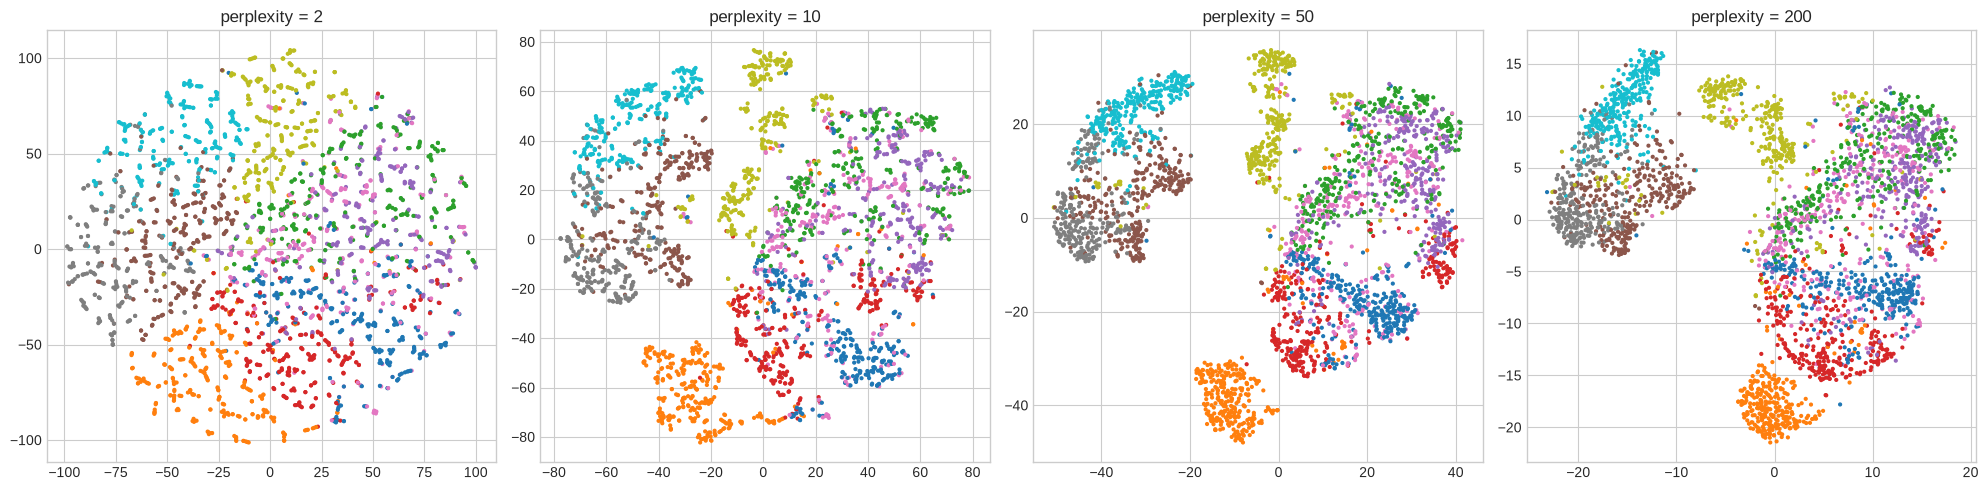

,perplexity,KL,trustworthiness(k=10),süre (sn)
0,2,1.176,0.983,9.320
1,10,1.211,0.991,10.062
2,50,0.925,0.991,12.528
3,200,0.571,0.987,21.324


YORUM: Çok küçük perplexity -> parça parça "adacıklar" (gürültüyü kümeleme); çok büyük -> kümeler birbirine yaklaşır, yerel ayrıntı kaybolur.
       KL'nin farklı perplexity'ler arasında karşılaştırılması adil değildir (P değişiyor); seçim için harita + trustworthiness birlikte bakılmalı.


In [23]:
# --- Perplexity duyarlılığı (n=3000 alt küme) ---
sub3k = RNG.choice(len(X_img), 3000, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(20, 5)); rows = []
for ax, perp in zip(axes, [2, 10, 50, 200]):
    t0 = time.time()
    m = TSNE(2, perplexity=perp, init='pca', learning_rate='auto', random_state=42, n_jobs=2).fit(Z50[sub3k])
    ax.scatter(m.embedding_[:, 0], m.embedding_[:, 1], c=y_fm[sub3k], cmap='tab10', s=4); ax.set_title(f'perplexity = {perp}')
    rows.append((perp, m.kl_divergence_, trustworthiness(Z50[sub3k], m.embedding_, n_neighbors=10), time.time() - t0))
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=['perplexity', 'KL', 'trustworthiness(k=10)', 'süre (sn)']).round(3))
print('YORUM: Çok küçük perplexity -> parça parça "adacıklar" (gürültüyü kümeleme); çok büyük -> kümeler birbirine yaklaşır, yerel ayrıntı kaybolur.')
print('       KL\'nin farklı perplexity\'ler arasında karşılaştırılması adil değildir (P değişiyor); seçim için harita + trustworthiness birlikte bakılmalı.')

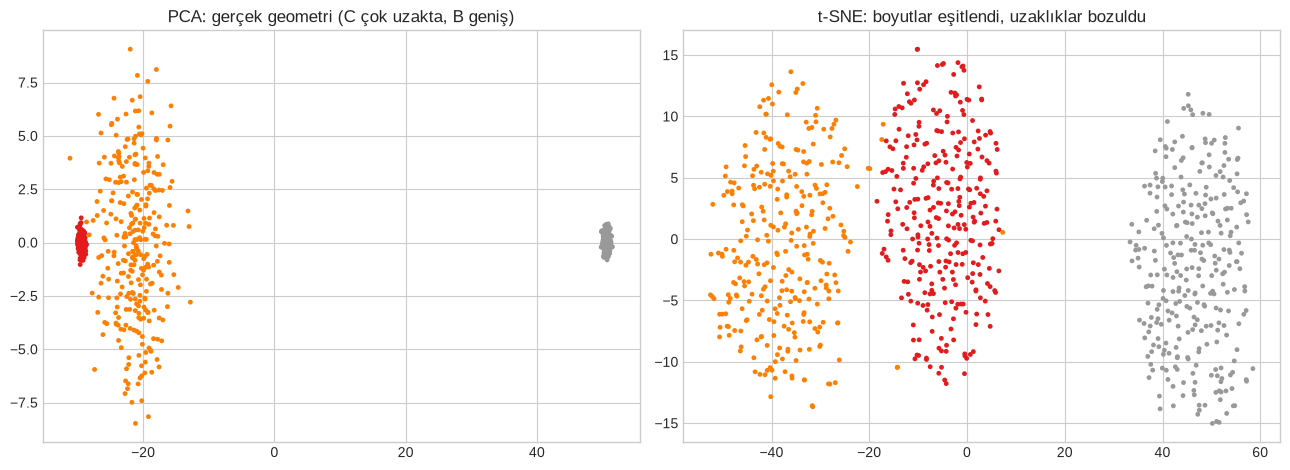

Gerçek küme yayılımları (std) :  [0.29, 2.96, 0.29]  -> B, A'nın ~10 katı
t-SNE'de küme yayılımları     :  [6.230000019073486, 7.150000095367432, 6.25]  -> fark çok daha az (yoğunluk eşitlendi)
Gerçek merkez uzaklık oranı C-A / B-A  : 9.9 | t-SNE'de: 1.6
YORUM: "Bu iki küme birbirine yakın / bu küme daha geniş" gibi çıkarımlar t-SNE (ve UMAP) haritasından yapılamaz.


In [24]:
# --- Yorum tuzağı: küme boyutu ve kümeler arası uzaklık t-SNE'de anlamsızdır ---
rs = np.random.RandomState(1)
dim = 10
c_small = rs.randn(300, dim) * 0.3                                 # sıkı küme
c_big   = rs.randn(300, dim) * 3.0 + np.r_[8, np.zeros(dim - 1)]   # geniş küme, 8 birim uzakta
c_far   = rs.randn(300, dim) * 0.3 + np.r_[80, np.zeros(dim - 1)]  # çok uzak (80 birim)
Xtrap = np.vstack([c_small, c_big, c_far]); ytrap = np.repeat([0, 1, 2], 300)
Ytrap = TSNE(2, perplexity=30, init='pca', learning_rate='auto', random_state=42).fit_transform(Xtrap)
Ypca = PCA(2).fit_transform(Xtrap)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, Y, ttl in zip(axes, [Ypca, Ytrap], ['PCA: gerçek geometri (C çok uzakta, B geniş)', 't-SNE: boyutlar eşitlendi, uzaklıklar bozuldu']):
    ax.scatter(Y[:, 0], Y[:, 1], c=ytrap, cmap='Set1', s=6); ax.set_title(ttl)
plt.tight_layout(); plt.show()
def spread(Y, lab): return [float(np.round(Y[lab == c].std(axis=0).mean(), 2)) for c in range(3)]
cent = lambda Y: np.array([Y[ytrap == c].mean(0) for c in range(3)])
print('Gerçek küme yayılımları (std) : ', spread(Xtrap[:, :2], ytrap), ' -> B, A\'nın ~10 katı')
print('t-SNE\'de küme yayılımları     : ', spread(Ytrap, ytrap), ' -> fark çok daha az (yoğunluk eşitlendi)')
cd = pairwise_distances(cent(Xtrap)); ct_ = pairwise_distances(cent(Ytrap))
print('Gerçek merkez uzaklık oranı C-A / B-A  :', round(float(cd[0, 2] / cd[0, 1]), 1), '| t-SNE\'de:', round(float(ct_[0, 2] / ct_[0, 1]), 1))
print('YORUM: "Bu iki küme birbirine yakın / bu küme daha geniş" gibi çıkarımlar t-SNE (ve UMAP) haritasından yapılamaz.')

## Adım 9 · UMAP: Elle Örnek, `n_neighbors` × `min_dist`, `transform` ve Denetimli UMAP

**Ne yapıyoruz?** (1) §8.3'teki bulanık kenar ağırlığı hesabını ($\rho,\ \sigma$, simetrikleştirme) elle yeniden üretiyoruz. (2) Tam 10.000 örnekte UMAP çalıştırıp
t-SNE ile **süreyi** karşılaştırıyoruz. (3) 3.000'lik alt kümede `n_neighbors` ve `min_dist` ızgarası çiziyoruz. (4) UMAP'in t-SNE'ye göre en büyük pratik
avantajını gösteriyoruz: **eğitimde görülmemiş** veriyi `transform` ile haritaya yerleştirmek (7.000 eğit / 3.000 yeni). (5) Etiketle beslenen **denetimli UMAP**.

In [25]:
# --- §8.3 elle örnek ---
d = np.array([1.0, 1.5, 3.0]); rho = d.min(); k_ = 3
f = lambda s: np.exp(-(d - rho) / s).sum() - np.log2(k_)
sigma = brentq(f, 1e-3, 50)
w = np.exp(-(d - rho) / sigma)
print(f'ρ = {rho} | hedef toplam log2(k) = {np.log2(k_):.4f} | σ = {sigma:.4f}')
print('Kenar ağırlıkları:', w.round(4), '| toplam =', w.sum().round(4), '(en yakın komşu = 1.0)')
a_, b_ = 0.6, 0.3
print(f'Simetrikleştirme (olasılıksal VEYA): a + b − ab = {a_ + b_ - a_ * b_:.2f}')

ρ = 1.0 | hedef toplam log2(k) = 1.5850 | σ = 0.7529
Kenar ağırlıkları: [1.     0.5148 0.0702] | toplam = 1.585 (en yakın komşu = 1.0)
Simetrikleştirme (olasılıksal VEYA): a + b − ab = 0.72


UMAP (n=10.000): 36 sn (ilk çağrı numba derlemesini de içerir) | t-SNE: 47 sn


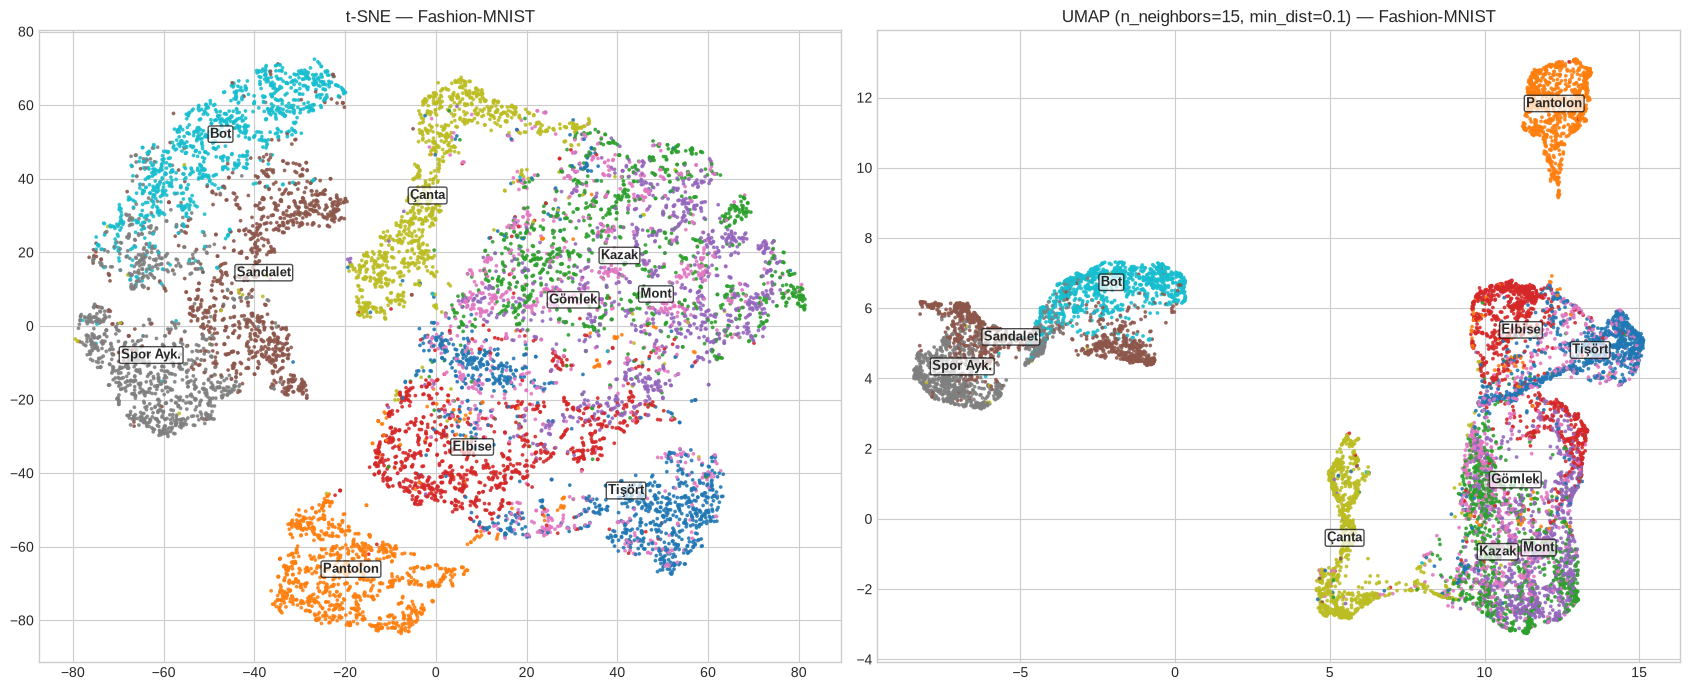

In [26]:
t0 = time.time()
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42, n_jobs=1)
Y_umap = reducer.fit_transform(Z50); T_umap = time.time() - t0
print('UMAP (n=10.000): %.0f sn (ilk çağrı numba derlemesini de içerir) | t-SNE: %.0f sn' % (T_umap, T_tsne))

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, Y, ttl in zip(axes, [Y_tsne, Y_umap], ['t-SNE', 'UMAP (n_neighbors=15, min_dist=0.1)']):
    ax.scatter(Y[:, 0], Y[:, 1], c=y_fm, cmap='tab10', s=3, alpha=0.8); ax.set_title(ttl + ' — Fashion-MNIST')
    for c in range(10):
        cx, cy = np.median(Y[y_fm == c], axis=0); ax.text(cx, cy, class_names[c], fontsize=9, weight='bold', ha='center', bbox=dict(facecolor='white', alpha=0.7, boxstyle='round,pad=0.15'))
plt.tight_layout(); plt.show()

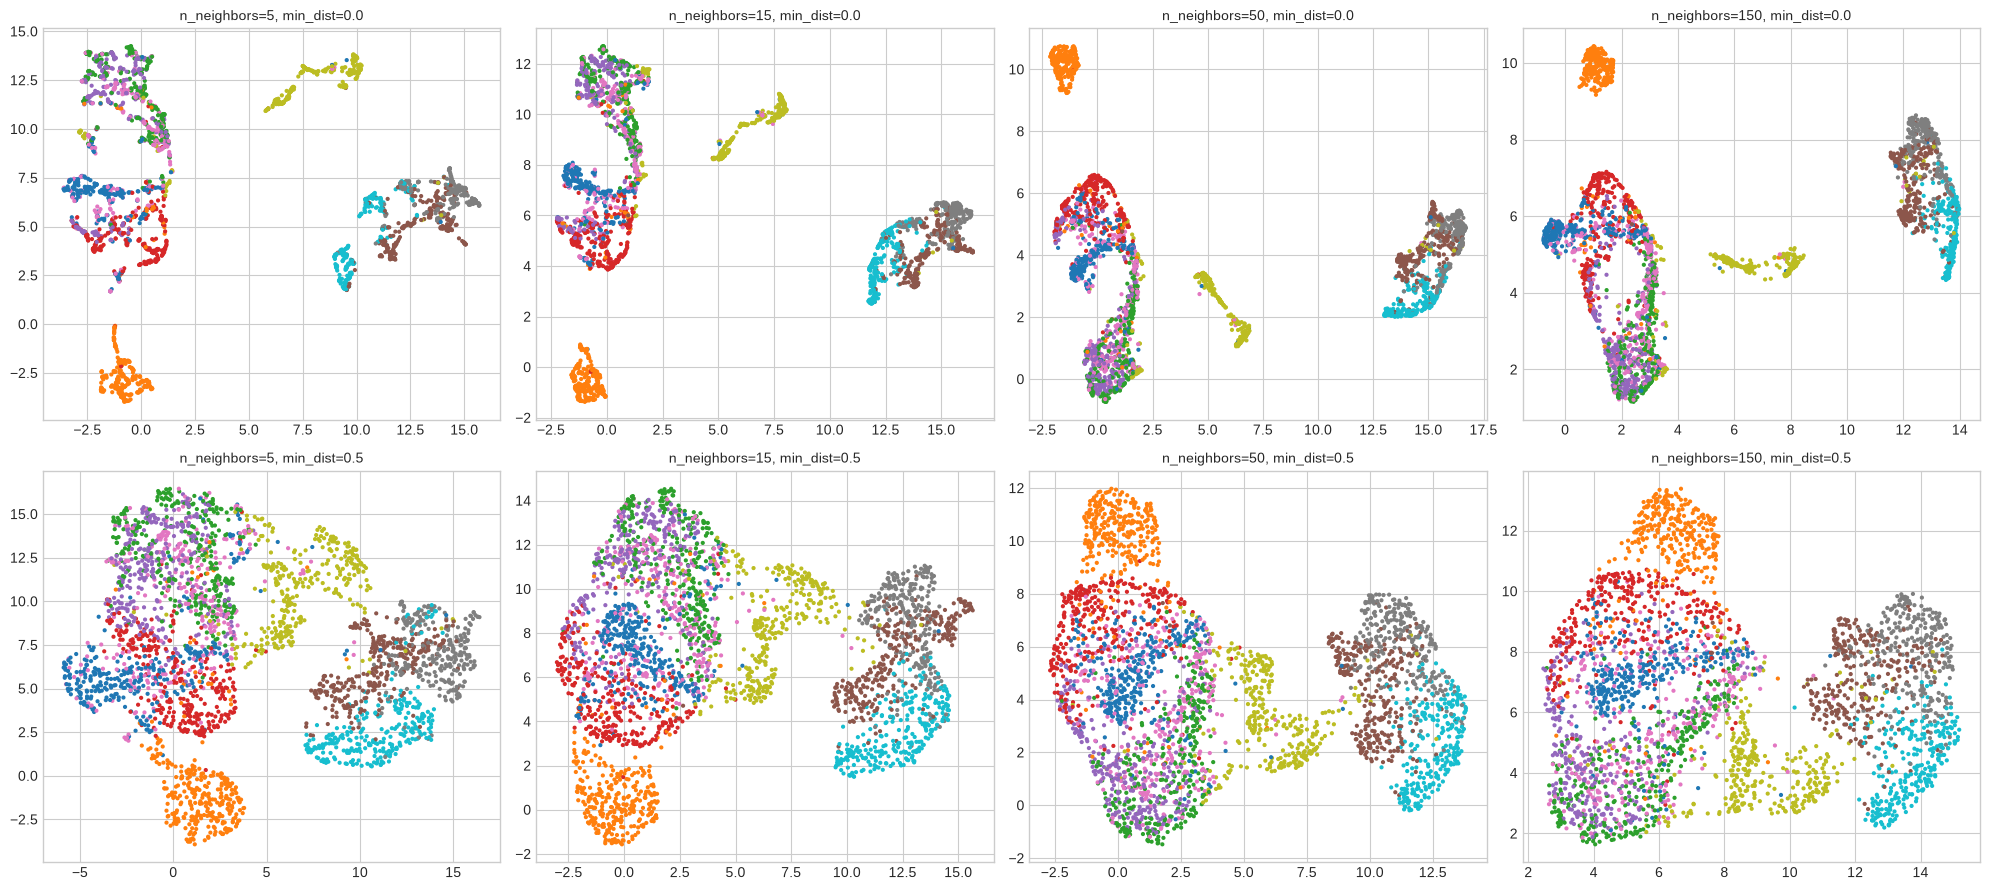

n_neighbors,5,15,50,150
min_dist,,,,
0.0,0.9878,0.9862,0.9838,0.9824
0.5,0.9798,0.9763,0.9744,0.9728


YORUM: min_dist noktaların haritada ne kadar sıkışacağını belirler; trustworthiness farkı küçük (≈0.01). n_neighbors büyüdükçe trustworthiness hafifçe düşüyor
       (daha global, daha yumuşak harita — yerel komşuluk ayrıntısı azalıyor). Tüm değerler 0.97+ : bu veri/ölçüt için UMAP ayarlara oldukça dayanıklı.


In [27]:
# --- n_neighbors x min_dist ızgarası (n=3000 alt küme) ---
Zsub = Z50[sub3k]; ysub = y_fm[sub3k]
fig, axes = plt.subplots(2, 4, figsize=(20, 9)); rows = []
for r, md_ in enumerate([0.0, 0.5]):
    for c, nn_ in enumerate([5, 15, 50, 150]):
        e = umap.UMAP(n_neighbors=nn_, min_dist=md_, random_state=42, n_jobs=1).fit_transform(Zsub)
        axes[r, c].scatter(e[:, 0], e[:, 1], c=ysub, cmap='tab10', s=4); axes[r, c].set_title(f'n_neighbors={nn_}, min_dist={md_}', fontsize=10)
        rows.append((nn_, md_, trustworthiness(Zsub, e, n_neighbors=10)))
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=['n_neighbors', 'min_dist', 'trustworthiness(k=10)']).pivot(index='min_dist', columns='n_neighbors', values='trustworthiness(k=10)').round(4))
print('YORUM: min_dist noktaların haritada ne kadar sıkışacağını belirler; trustworthiness farkı küçük (≈0.01). n_neighbors büyüdükçe trustworthiness hafifçe düşüyor')
print('       (daha global, daha yumuşak harita — yerel komşuluk ayrıntısı azalıyor). Tüm değerler 0.97+ : bu veri/ölçüt için UMAP ayarlara oldukça dayanıklı.')

2B UMAP (transform ile yeni veri)  + kNN test doğruluğu: 0.7570
2B PCA                              + kNN test doğruluğu: 0.5400
hasattr(TSNE, "transform"): False   <- klasik t-SNE yeni veriyi dönüştüremez


Denetimli UMAP (y verildi) + kNN test doğruluğu: 0.7993


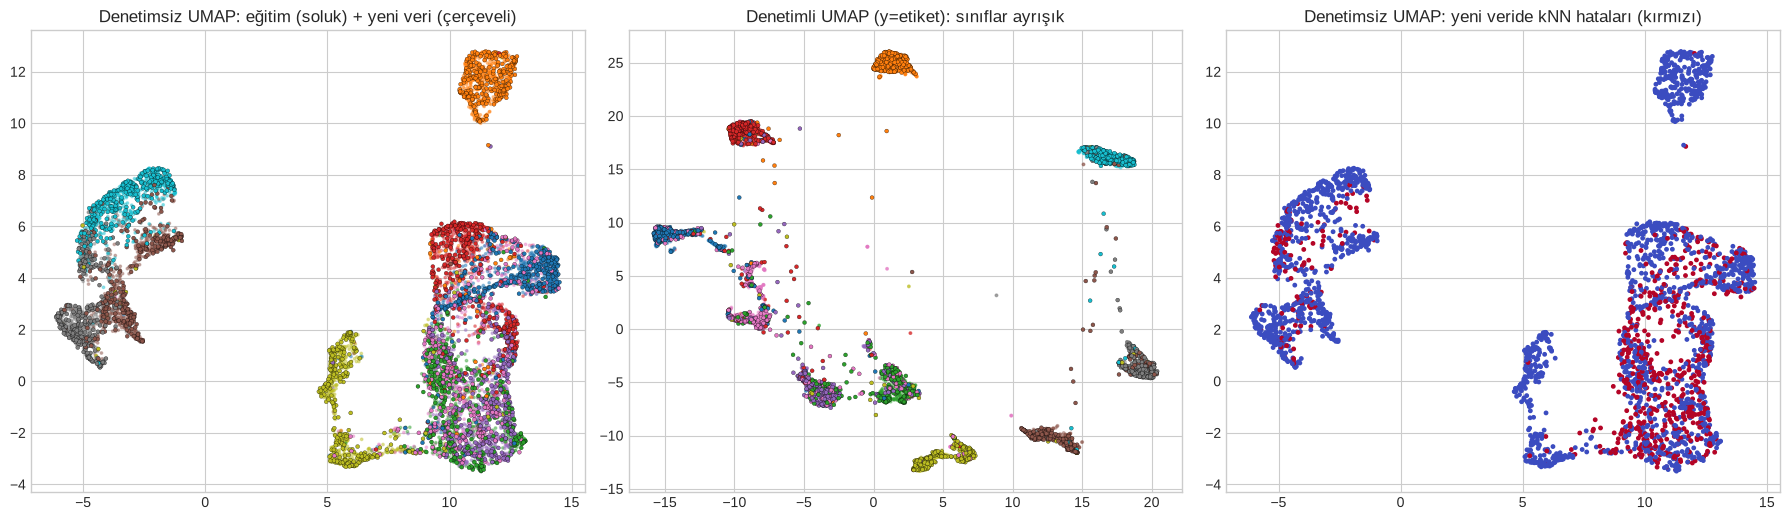

In [28]:
# --- transform: eğitimde görülmeyen veriyi yerleştirme (t-SNE bunu yapamaz) ---
Ztr_, Zte_, ytr_, yte_ = train_test_split(Z50, y_fm, test_size=0.3, stratify=y_fm, random_state=42)
um = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1).fit(Ztr_)
E_tr, E_te = um.embedding_, um.transform(Zte_)
acc_umap = KNeighborsClassifier(15).fit(E_tr, ytr_).score(E_te, yte_)
pca2 = PCA(2, random_state=42).fit(Ztr_)
acc_pca2 = KNeighborsClassifier(15).fit(pca2.transform(Ztr_), ytr_).score(pca2.transform(Zte_), yte_)
print('2B UMAP (transform ile yeni veri)  + kNN test doğruluğu: %.4f' % acc_umap)
print('2B PCA                              + kNN test doğruluğu: %.4f' % acc_pca2)
print('hasattr(TSNE, "transform"):', hasattr(TSNE(), 'transform'), '  <- klasik t-SNE yeni veriyi dönüştüremez')

# --- denetimli UMAP ---
t0 = time.time(); um_sup = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1).fit(Ztr_, y=ytr_); t_sup = time.time() - t0
E_tr_s, E_te_s = um_sup.embedding_, um_sup.transform(Zte_)
print('Denetimli UMAP (y verildi) + kNN test doğruluğu: %.4f' % KNeighborsClassifier(15).fit(E_tr_s, ytr_).score(E_te_s, yte_))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
axes[0].scatter(E_tr[:, 0], E_tr[:, 1], c=ytr_, cmap='tab10', s=3, alpha=0.4); axes[0].scatter(E_te[:, 0], E_te[:, 1], c=yte_, cmap='tab10', s=8, edgecolor='k', linewidth=0.2)
axes[0].set_title('Denetimsiz UMAP: eğitim (soluk) + yeni veri (çerçeveli)')
axes[1].scatter(E_tr_s[:, 0], E_tr_s[:, 1], c=ytr_, cmap='tab10', s=3, alpha=0.4); axes[1].scatter(E_te_s[:, 0], E_te_s[:, 1], c=yte_, cmap='tab10', s=8, edgecolor='k', linewidth=0.2)
axes[1].set_title('Denetimli UMAP (y=etiket): sınıflar ayrışık')
axes[2].scatter(E_te[:, 0], E_te[:, 1], c=(KNeighborsClassifier(15).fit(E_tr, ytr_).predict(E_te) != yte_), cmap='coolwarm', s=6)
axes[2].set_title('Denetimsiz UMAP: yeni veride kNN hataları (kırmızı)')
plt.tight_layout(); plt.show()

## Adım 10 · Niceliksel Karşılaştırma: Trustworthiness, Continuity, kNN Doğruluğu ve Süre

**Ne yapıyoruz?** Sekiz yöntemi **aynı 3.000 örnek** ve **2 boyut** üzerinde karşılaştırıyoruz: PCA, LDA (etiketli), Kernel PCA (RBF), NMF, ICA, t-SNE, UMAP,
denetimli UMAP (etiketli). Ölçütler: **trustworthiness** (2B'de komşu görünenler gerçekten komşu mu) ve **continuity** (yüksek boyuttaki komşular 2B'de korunmuş mu —
trustworthiness'ın argümanları yer değiştirerek hesaplanır) — her ikisi de ham 784 piksel uzayına göre, $k=10$; ve 2B gömme üzerinde 5-katlı kNN doğruluğu.
**Uyarı (dürüstlük):** t-SNE/UMAP'te kNN doğruluğu *transduktif* ölçülür (hepsi birlikte gömüldü); LDA ve denetimli UMAP etiket kullandığı için ayrı bir grup olarak okunmalı.

In [29]:
Xq, yq = X_img[sub3k], y_fm[sub3k]
Zq = Z50[sub3k]

def continuity(X_high, X_low, k=10):
    """Continuity = trustworthiness(X_low, X_high) (roller yer değiştirir)."""
    return trustworthiness(X_low, X_high, n_neighbors=k)

results, embeds = [], {}
def run(name, fn, supervised=False):
    t0 = time.time(); E = fn(); dt = time.time() - t0
    acc = cross_val_score(KNeighborsClassifier(15), E, yq, cv=5).mean()
    results.append((name, 'etiketli' if supervised else 'etiketsiz', trustworthiness(Xq, E, n_neighbors=10), continuity(Xq, E), acc, dt)); embeds[name] = E

run('PCA', lambda: PCA(2, random_state=42).fit_transform(Zq))
run('LDA', lambda: LinearDiscriminantAnalysis(solver='eigen', n_components=2).fit(Zq, yq).transform(Zq), True)
gam_q = 1 / (2 * np.median(pairwise_distances(Zq[:500])) ** 2)
run('Kernel PCA (RBF)', lambda: KernelPCA(2, kernel='rbf', gamma=gam_q).fit_transform(Zq))
run('NMF', lambda: NMF(2, init='nndsvda', max_iter=400, random_state=0).fit_transform(Xq))
run('ICA', lambda: FastICA(2, whiten='unit-variance', random_state=0, max_iter=1000).fit_transform(Zq))
run('t-SNE', lambda: TSNE(2, perplexity=30, init='pca', learning_rate='auto', random_state=42, n_jobs=2).fit_transform(Zq))
run('UMAP', lambda: umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1).fit_transform(Zq))
run('UMAP (denetimli)', lambda: umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1).fit_transform(Zq, y=yq), True)

res = pd.DataFrame(results, columns=['Yöntem', 'Etiket kullanımı', 'Trustworthiness', 'Continuity', 'kNN doğruluğu (5-kat, 2B)', 'Süre (sn)'])
display(res.sort_values('Trustworthiness', ascending=False).round(3).reset_index(drop=True))

,Yöntem,Etiket kullanımı,Trustworthiness,Continuity,"kNN doğruluğu (5-kat, 2B)",Süre (sn)
0,t-SNE,etiketsiz,0.987,0.981,0.765,10.997
1,UMAP,etiketsiz,0.979,0.981,0.758,11.247
2,UMAP (denetimli),etiketli,0.975,0.913,0.978,11.158
3,PCA,etiketsiz,0.912,0.970,0.530,0.002
4,ICA,etiketsiz,0.912,0.971,0.537,0.021
5,Kernel PCA (RBF),etiketsiz,0.910,0.970,0.526,0.307
6,NMF,etiketsiz,0.905,0.964,0.479,0.550
7,LDA,etiketli,0.800,0.904,0.543,0.013


## Adım 11 · Sentez: Sekiz Yöntem Yan Yana

**Ne yapıyoruz?** Adım 10'daki sekiz gömmeyi aynı 3.000 örnek üzerinde, aynı renk kodlamasıyla yan yana çiziyoruz. Kural: *tek bir haritaya değil*, harita **ve** niceliksel
tabloya birlikte bakıp karar veriyoruz.

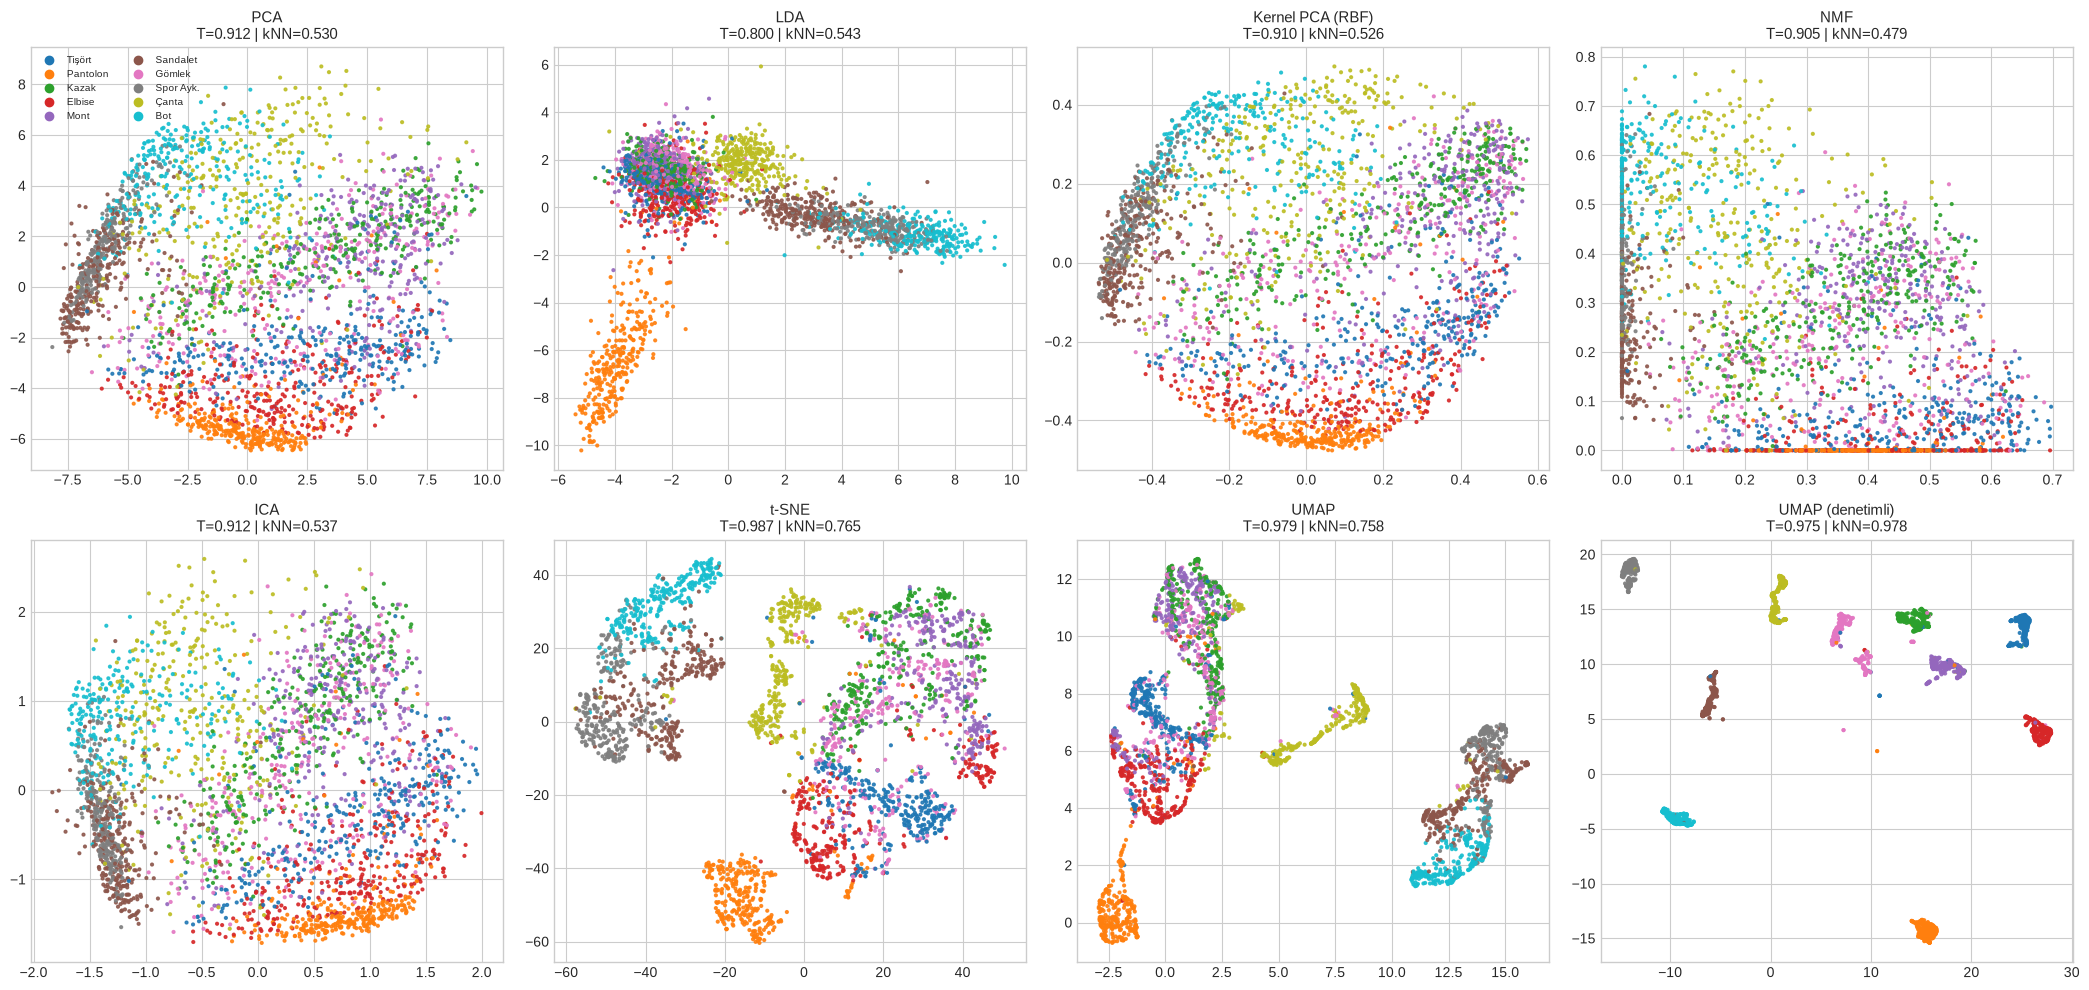

SONUÇ: (1) Doğrusal yöntemler (PCA/ICA/NMF) ve Kernel PCA 2B'de benzer, düşük trustworthiness (≈0.91) ve kNN doğruluğu (≈0.5) verir;
(2) t-SNE ve UMAP yerel komşulukları belirgin biçimde daha iyi korur (trustworthiness ≈0.98-0.99, kNN ≈0.76); UMAP ayrıca yeni veriye uygulanabilir;
(3) LDA 2B'de 9 ayrıştırıcı eksenin yalnızca 2'sini tutar — Adım 2'de 9 eksenle 0.80 doğruluk vardı; "etiketli = her zaman daha iyi 2B harita" değildir;
(4) Denetimli UMAP'in 0.978'lik kNN doğruluğu ADİL DEĞİL: etiketi gömmenin içine kattığı için (ve ölçüm transduktif olduğu için) neredeyse tautolojiktir —
    gerçek genelleme ölçümü Adım 9'daki ayrılmış test kümesi (0.80) ile yapıldı.


In [30]:
fig, axes = plt.subplots(2, 4, figsize=(21, 10))
for ax, (name, E) in zip(axes.ravel(), embeds.items()):
    ax.scatter(E[:, 0], E[:, 1], c=yq, cmap='tab10', s=4, alpha=0.85)
    r = res[res['Yöntem'] == name].iloc[0]
    ax.set_title(f'{name}\nT={r["Trustworthiness"]:.3f} | kNN={r["kNN doğruluğu (5-kat, 2B)"]:.3f}', fontsize=11)
axes[0, 0].legend(handles=[plt.Line2D([], [], marker='o', ls='', color=plt.cm.tab10(c / 9), label=class_names[c]) for c in range(10)], fontsize=7, ncol=2, loc='best')
plt.tight_layout(); plt.show()
print('SONUÇ: (1) Doğrusal yöntemler (PCA/ICA/NMF) ve Kernel PCA 2B\'de benzer, düşük trustworthiness (≈0.91) ve kNN doğruluğu (≈0.5) verir;')
print('(2) t-SNE ve UMAP yerel komşulukları belirgin biçimde daha iyi korur (trustworthiness ≈0.98-0.99, kNN ≈0.76); UMAP ayrıca yeni veriye uygulanabilir;')
print('(3) LDA 2B\'de 9 ayrıştırıcı eksenin yalnızca 2\'sini tutar — Adım 2\'de 9 eksenle 0.80 doğruluk vardı; "etiketli = her zaman daha iyi 2B harita" değildir;')
print('(4) Denetimli UMAP\'in 0.978\'lik kNN doğruluğu ADİL DEĞİL: etiketi gömmenin içine kattığı için (ve ölçüm transduktif olduğu için) neredeyse tautolojiktir —')
print('    gerçek genelleme ölçümü Adım 9\'daki ayrılmış test kümesi (0.80) ile yapıldı.')

# 📊 R Uygulaması

R'da bu yöntemlerin her biri için olgun paketler var: **`kernlab::kpca`** (Kernel PCA'nın referans uygulaması), **`fastICA`** (FastICA'nın orijinal R portu),
**`Rtsne`** (Barnes-Hut t-SNE) ve **`uwot`** (UMAP'in R uygulaması). Proje kararı gereği (bkz. [[notebook_style_convention]]) R bölümünü kısa tutuyoruz:
1 hücre Kernel PCA + FastICA (Python'da kullandığımız `make_circles` ve kokteyl partisi verisi), 1 hücre `Rtsne` + `uwot` (Fashion-MNIST alt kümesi).

In [ ]:
%load_ext rpy2.ipython
circles_for_r = pd.DataFrame(Xc, columns=['x1', 'x2']); circles_for_r['y'] = yc
mix_for_r = pd.DataFrame(X_mix, columns=['m1', 'm2', 'm3'])
src_for_r = pd.DataFrame(S_true, columns=['s1', 's2', 's3'])
fm_for_r = pd.DataFrame(Z50[sub3k]); fm_for_r['label'] = y_fm[sub3k]

In [ ]:
%%R -i circles_for_r,mix_for_r,src_for_r -w 900 -h 400
# install.packages(c("kernlab", "fastICA"))  # ilk çalıştırmada gerekir
library(kernlab); library(fastICA)
# Kernel PCA: sigma = 1/sqrt(2*gamma) ilişkisi -> kernlab'ın "rbfdot" sigma'sı = gamma (exp(-sigma ||x-y||^2))
kp <- kpca(~x1 + x2, data = circles_for_r, kernel = "rbfdot", kpar = list(sigma = 10), features = 2)
Z <- rotated(kp)
cat("Kernel PCA ilk bileşen — sınıf 0 ort.:", round(mean(Z[circles_for_r$y == 0, 1]), 3),
    "| sınıf 1 ort.:", round(mean(Z[circles_for_r$y == 1, 1]), 3), "\n")
par(mfrow = c(1, 2)); plot(Z[, 1], Z[, 2], col = circles_for_r$y + 1, pch = 19, cex = .5, main = "R: kernlab::kpca")
# FastICA (kokteyl partisi)
ica <- fastICA(as.matrix(mix_for_r), n.comp = 3, alg.typ = "deflation", fun = "logcosh", method = "R")
cormat <- abs(cor(ica$S, as.matrix(src_for_r)))
cat("FastICA |korelasyon| matrisi (kaynaklar vs bulunan):\n"); print(round(cormat, 3))
matplot(ica$S[1:800, ], type = "l", lty = 1, main = "R: fastICA ile kurtarılan kaynaklar")

In [ ]:
%%R -i fm_for_r -w 900 -h 450
# install.packages(c("Rtsne", "uwot"))
library(Rtsne); library(uwot)
X <- as.matrix(fm_for_r[, 1:50]); lab <- fm_for_r$label
set.seed(42)
ts <- Rtsne(X, dims = 2, perplexity = 30, pca = FALSE, check_duplicates = FALSE, num_threads = 2)
um <- umap(X, n_neighbors = 15, min_dist = 0.1, n_components = 2, ret_model = FALSE)
par(mfrow = c(1, 2))
plot(ts$Y, col = lab + 1, pch = 19, cex = .4, main = "R: Rtsne (perplexity=30)")
plot(um,   col = lab + 1, pch = 19, cex = .4, main = "R: uwot::umap")

# 🗄️ SQL Uygulaması (DuckDB)

Bu serinin tekrar eden desenini (bkz. [[classical_ml_progress]] "SQL ile Model Inference'ının Yeniden Üretimi") iki **aydınlatıcı** noktada uyguluyoruz;
proje kararı gereği (bkz. [[notebook_style_convention]]) ikisi de tek hücre:

1. **LDA izdüşümü = ağırlıklı toplam:** Fit edilmiş LDA'nın `scalings_` matrisini tabloya koyup 10.000 görüntünün (PCA(50) uzayında) LDA koordinatlarını
   `JOIN` + `GROUP BY` + `SUM(x*w)` ile hesaplıyoruz — bir boyut indirgemenin üretimde basit bir **matris çarpımı** olduğunu gösterir.
2. **Kernel PCA'nın `transform`'u:** Yeni noktaların eğitim noktalarına **RBF kernel satırı** (`CROSS JOIN` + `EXP`), merkezleme ve $\sum_i a_{ij}\tilde{k}$ toplamı SQL'de.

In [34]:
import duckdb
con = duckdb.connect()

# --- SQL-1: LDA izdüşümü (10.000 görüntü, PCA(50) uzayı, 9 eksen) ---
n_, p_ = Z50.shape
samples = pd.DataFrame({'id': np.repeat(np.arange(n_), p_), 'dim': np.tile(np.arange(p_), n_), 'val': Z50.ravel()})
Wl = lda_full.scalings_[:, :9]
loadings = pd.DataFrame({'dim': np.repeat(np.arange(p_), 9), 'comp': np.tile(np.arange(9), p_), 'w': Wl.ravel()})
con.register('samples', samples); con.register('loadings', loadings)
lda_sql = con.execute("""
    SELECT s.id, l.comp, SUM(s.val * l.w) AS z       -- solver='eigen': transform = X @ scalings_
    FROM samples s JOIN loadings l ON s.dim = l.dim
    GROUP BY s.id, l.comp ORDER BY s.id, l.comp
""").df()
Z_lda_sql = lda_sql.pivot(index='id', columns='comp', values='z').to_numpy()
print('SQL LDA koordinatları şekli:', Z_lda_sql.shape)
print('sklearn lda.transform ile maks. mutlak fark: %.2e' % np.abs(Z_lda_sql - lda_full.transform(Z50)[:, :9]).max())
print('\nYORUM: Boyut indirgemenin çıkarım (inference) adımı SQL\'de tek bir JOIN + SUM(x*w). Model, bir "ağırlık tablosu"na indirgendi;')
print('       10.000 satır × 50 boyut × 9 eksen = 4,5 milyon çarpım veritabanında hesaplandı.')

SQL LDA koordinatları şekli: (10000, 9)
sklearn lda.transform ile maks. mutlak fark: 3.55e-15

YORUM: Boyut indirgemenin çıkarım (inference) adımı SQL'de tek bir JOIN + SUM(x*w). Model, bir "ağırlık tablosu"na indirgendi;
       10.000 satır × 50 boyut × 9 eksen = 4,5 milyon çarpım veritabanında hesaplandı.


In [35]:
# --- SQL-2: Kernel PCA transform (yeni 200 nokta, 1000 eğitim noktası, γ=3) ---
train = pd.DataFrame({'i': np.arange(len(Xc)), 'x1': Xc[:, 0], 'x2': Xc[:, 1]})
newp = pd.DataFrame({'j': np.arange(len(Xnew)), 'x1': Xnew[:, 0], 'x2': Xnew[:, 1]})
alpha = pd.DataFrame({'i': np.repeat(np.arange(len(Xc)), 2), 'c': np.tile([0, 1], len(Xc)), 'a': my_kp.A_.ravel(),
                      'lam': np.tile(my_kp.lam_, len(Xc))})
colmean = pd.DataFrame({'i': np.arange(len(Xc)), 'cm': my_kp.K_col_mean_})
for nm, df in [('train', train), ('newp', newp), ('alpha', alpha), ('colmean', colmean)]: con.register(nm, df)
sql_kpca = f"""
WITH kern AS (
    SELECT n.j, t.i, EXP(-{my_kp.gamma} * (POWER(n.x1 - t.x1, 2) + POWER(n.x2 - t.x2, 2))) AS k
    FROM newp n CROSS JOIN train t
), rowmean AS (SELECT j, AVG(k) AS rm FROM kern GROUP BY j),
kc AS (
    SELECT k.j, k.i, k.k - r.rm - c.cm + {my_kp.K_col_mean_.mean()} AS kc
    FROM kern k JOIN rowmean r USING (j) JOIN colmean c USING (i)
)
SELECT kc.j, a.c, SUM(kc.kc * a.a) / SQRT(ANY_VALUE(a.lam)) AS z
FROM kc JOIN alpha a USING (i)
GROUP BY kc.j, a.c ORDER BY kc.j, a.c
"""
kp_sql = con.execute(sql_kpca).df().pivot(index='j', columns='c', values='z').to_numpy()
print('SQL Kernel PCA transform şekli:', kp_sql.shape)
print('Sıfırdan SimpleKernelPCA.transform ile maks. fark: %.2e' % np.abs(kp_sql - my_kp.transform(Xnew)).max())
print('\nYORUM: Kernel PCA\'nın "modeli" = eğitim noktaları + alfa tablosu. Yeni nokta, bütün eğitim noktalarıyla CROSS JOIN edilir (O(n·m)),')
print('       bu yüzden Kernel PCA üretimde pahalıdır — PCA/LDA gibi küçük ağırlık matrisi yerine tüm eğitim kümesini taşımak zorundayız.')

SQL Kernel PCA transform şekli: (200, 2)
Sıfırdan SimpleKernelPCA.transform ile maks. fark: 1.33e-15

YORUM: Kernel PCA'nın "modeli" = eğitim noktaları + alfa tablosu. Yeni nokta, bütün eğitim noktalarıyla CROSS JOIN edilir (O(n·m)),
       bu yüzden Kernel PCA üretimde pahalıdır — PCA/LDA gibi küçük ağırlık matrisi yerine tüm eğitim kümesini taşımak zorundayız.


## ✏️ Egzersizler

Hepsi bu notebook'ta tanımlı değişkenlerle ve **hazır modellerle** çözülebilir (sıfırdan kod yazmak gerekmiyor). Her egzersizin kod hücresinde, **nasıl yapılacağını adım adım
gösteren `# TODO` yönlendirmeleri** var — çözüm yok; TODO'ları kod satırlarına çevirmek senin işin. Her egzersizde kodun altına 1-2 cümlelik yorumunu da yaz.

**E1.** Olivetti yüzlerinde (`X_face`) varyansın %90'ını koruyan PCA kaç bileşen gerektirir? Aynı yüzü (örn. `X_face[0]`) 5, 25 ve bu bileşen sayısıyla
yeniden yapılandır ve her biri için ortalama kareli hatayı (MSE) yazdır. Bileşen sayısı arttıkça hata nasıl değişiyor?

In [36]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `PCA(n_components=0.90, svd_solver='full')` ile `X_face` üzerinde fit et; `.n_components_`
#         değerini yazdır.
# TODO 2: Bir döngüyle `k in [5, 25, n90]` için `PCA(n_components=k).fit(X_face)` kur.
# TODO 3: Yeniden yapılandırma: `Z = pca_k.transform(X_face[[0]])`, sonra `pca_k.inverse_transform(Z)`.
# TODO 4: `mse = ((X_face[0] - X_rec[0]) ** 2).mean()` ile hatayı hesapla ve bir tabloya ekle.
# TODO 5: (İsteğe bağlı) `plt.imshow(X_rec.reshape(64, 64), cmap='gray')` ile 3 yeniden yapılandırmayı yan
#         yana çiz.

**E2.** `make_moons(n_samples=1000, noise=0.1, random_state=42)` verisinde (iki hilal) Kernel PCA'yı `gamma ∈ {0.1, 1, 5, 20}` için çalıştır (`n_components=2`, RBF).
Her biri için ilk iki bileşen üzerinde `LogisticRegression` 5-katlı CV doğruluğunu hesapla ve doğrusal PCA ile karşılaştır. En iyi γ hangisi?

In [37]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `X_m, y_m = make_moons(...)` ile veriyi üret.
# TODO 2: Doğrusal baz: `Z = PCA(2).fit_transform(X_m)`; `cross_val_score(LogisticRegression(), Z, y_m,
#         cv=5).mean()`.
# TODO 3: Döngü: `for g in [0.1, 1, 5, 20]: Z = KernelPCA(2, kernel='rbf', gamma=g).fit_transform(X_m)`.
# TODO 4: Her γ için aynı `cross_val_score` ile doğruluğu hesapla, `(g, acc)` çiftlerini bir DataFrame'e
#         topla.
# TODO 5: En yüksek doğruluğu veren γ'yı `idxmax()` ile bul; neden çok küçük ve çok büyük γ'nın kötü
#         olduğunu 1-2 cümleyle yorumla (§4.4).

**E3.** Haber verisinde (`V_txt`, `vocab`) NMF'i **10 konu** ile yeniden çalıştır. Her konunun en yüksek 8 kelimesini yazdır. 6 konulu sonuçla kıyasla: hangi
gerçek kategori birden fazla konuya bölündü? Konu saflığını (`purity`) 6 konulu sonuçla karşılaştır.

In [38]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `nmf10 = NMF(n_components=10, init='nndsvda', max_iter=400, random_state=42)`; `W10 =
#         nmf10.fit_transform(V_txt)`.
# TODO 2: Konu kelimeleri için `np.argsort(nmf10.components_[t])[::-1][:8]` ile `vocab` içinden kelimeleri
#         seç.
# TODO 3: Baskın konu: `news['topic10'] = W10.argmax(axis=1)`; `pd.crosstab(news['target'],
#         news['topic10'])`.
# TODO 4: Purity: `ct.max(axis=0).sum() / ct.values.sum()` (Adım 5'teki gibi).
# TODO 5: Çapraz tabloda bir kategorinin satırında iki büyük sayı varsa o kategori bölünmüş demektir;
#         hangi kategori ve neden olabilir?

**E4.** Kokteyl partisinde 3 kaynak var ama sadece **2 mikrofonun** kaydını kullan (`X_mix[:, :2]`). `FastICA(n_components=2)` ile kaynakları kurtarmayı dene ve
gerçek kaynaklarla (`S_true`) |korelasyon| matrisini yazdır. 3 kaynağın tamamı kurtarılabildi mi? Neden?

In [39]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: `X_two = X_mix[:, :2]`; `ica2 = FastICA(n_components=2, whiten='unit-variance', random_state=0,
#         max_iter=1000)`; `S2 = ica2.fit_transform(X_two)`.
# TODO 2: Korelasyon: `np.abs(np.corrcoef(S2.T, S_true.T)[:2, 2:])` — (bulunan 2 bileşen × 3 gerçek
#         kaynak) matrisi.
# TODO 3: Her satırın (bulunan bileşenin) en yüksek korelasyonunu `max(axis=1)` ile bul; ≈1 mi, yoksa
#         karışık mı?
# TODO 4: Bilgi: gözlem sayısı (2) kaynak sayısından (3) az olan *eksik belirlenmiş* (underdetermined)
#         problemde `x = A s` ile `s` tek anlamlı çözülemez.
# TODO 5: Yorum: ICA, kaynak sayısı ≤ mikrofon sayısı koşulunda çalışır; yanıtında bunu kendi gözlemine
#         bağla.

**E5.** `Z50[sub3k]` üzerinde t-SNE'yi `init='random'` ve `init='pca'` ile, her biri için 3 farklı `random_state` (0, 1, 2) kullanarak çalıştır. Her koşul için
trustworthiness'ı hesapla; hangi başlatma daha **tutarlı** (düşük std) ve ortalama olarak daha iyi?

In [40]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: İç içe döngü: `for init in ['random', 'pca']: for seed in [0, 1, 2]:`.
# TODO 2: `TSNE(2, perplexity=30, init=init, learning_rate='auto', random_state=seed,
#         n_jobs=2).fit_transform(Z50[sub3k])`.
# TODO 3: `trustworthiness(Z50[sub3k], emb, n_neighbors=10)` ile skoru hesapla; `(init, seed, score)`
#         satırlarını listeye ekle.
# TODO 4: `pd.DataFrame(...).groupby('init')['score'].agg(['mean', 'std'])` ile özetle.
# TODO 5: Yorum: `init='pca'` neden global yapıyı daha kararlı koruyor? (§7.4'ün son maddesine bak.)

**E6.** Denetimsiz UMAP'i `n_components ∈ {2, 5, 10, 20}` ile Adım 9'daki `Ztr_` üzerinde eğit, `Zte_`'yi `transform` et ve her boyut için kNN test doğruluğunu hesapla.
Ham `Z50` (50 boyut) üzerindeki kNN doğruluğu ile kıyasla. Kaç boyuta kadar indirgemek "bedava"?

In [41]:
# Kodunu buraya yaz — aşağıdaki TODO adımlarını sırayla uygula (çözüm verilmedi)
# TODO 1: Döngü: `for d in [2, 5, 10, 20]: um = umap.UMAP(n_components=d, n_neighbors=15, min_dist=0.1,
#         random_state=42, n_jobs=1).fit(Ztr_)`.
# TODO 2: `E_tr = um.embedding_`; `E_te = um.transform(Zte_)`.
# TODO 3: `KNeighborsClassifier(15).fit(E_tr, ytr_).score(E_te, yte_)` ile doğruluğu hesapla.
# TODO 4: Referans: `KNeighborsClassifier(15).fit(Ztr_, ytr_).score(Zte_, yte_)` (50 boyutlu PCA girdisi).
# TODO 5: Sonuçları `(d, acc)` tablosuna koy; doğruluk hangi boyutta ham 50B seviyesine yaklaşıyor? Bu,
#         UMAP'i görselleştirme dışında özellik çıkarımı için kullanmanın gerekçesi mi?

## 📚 Kaynaklar

| Kaynak | Bölüm | Notlar |
|---|---|---|
| [Fisher (1936) — "The Use of Multiple Measurements in Taxonomic Problems", *Annals of Eugenics*](https://doi.org/10.1111/j.1469-1809.1936.tb02137.x) | LDA | LDA'nın orijinal makalesi (iris verisinin ilk kullanımı) |
| [Belhumeur, Hespanha, Kriegman (1997) — "Eigenfaces vs. Fisherfaces", *IEEE TPAMI*](https://doi.org/10.1109/34.598228) | PCA→LDA boru hattı | LDA'nın yüz tanımada (Fisherfaces) uygulaması |
| [Schölkopf, Smola, Müller (1998) — "Nonlinear Component Analysis as a Kernel Eigenvalue Problem", *Neural Computation*](https://doi.org/10.1162/089976698300017467) | Kernel PCA | Kernel PCA'nın orijinal makalesi |
| [Lee & Seung (1999) — "Learning the parts of objects by non-negative matrix factorization", *Nature*](https://doi.org/10.1038/44565) | NMF | NMF'in orijinal makalesi; yüz "parçaları" deneyi |
| [Alexandrov ve ark. (2013) — "Signatures of mutational processes in human cancer", *Nature*](https://doi.org/10.1038/nature12477) | NMF uygulaması | NMF ile kanser mutasyon imzaları (COSMIC) |
| [Hyvärinen & Oja (2000) — "Independent component analysis: algorithms and applications", *Neural Networks*](https://doi.org/10.1016/S0893-6080(00)00026-5) | ICA / FastICA | ICA'nın standart tanıtım makalesi (kurtosis, negentropi, FastICA) |
| [Bartlett, Movellan, Sejnowski (2002) — "Face recognition by independent component analysis", *IEEE TNN*](https://doi.org/10.1109/TNN.2002.804287) | ICA mimari I | Yüzlerde ICA'nın iki mimarisi |
| [van der Maaten & Hinton (2008) — "Visualizing Data using t-SNE", *JMLR*](https://jmlr.org/papers/v9/vandermaaten08a.html) | t-SNE | t-SNE'nin orijinal makalesi |
| [Wattenberg, Viégas, Johnson (2016) — "How to Use t-SNE Effectively", *Distill*](https://distill.pub/2016/misread-tsne/) | t-SNE yorum tuzakları | İnteraktif; perplexity, küme boyutu/uzaklığı yanılgıları |
| [McInnes, Healy, Melville (2018) — "UMAP: Uniform Manifold Approximation and Projection"](https://arxiv.org/abs/1802.03426) | UMAP | UMAP'in orijinal makalesi |
| [UMAP — resmi dokümantasyon](https://umap-learn.readthedocs.io/) | UMAP | `n_neighbors`/`min_dist` rehberi, `transform`, denetimli UMAP |
| [Chari & Pachter (2023) — "The specious art of single-cell genomics", *PLOS Comp. Biol.*](https://doi.org/10.1371/journal.pcbi.1011288) | t-SNE/UMAP eleştirisi | 2B gömmelerin yanıltıcı olabileceği; niceliksel doğrulama gerekçesi |
| [scikit-learn — Decomposition](https://scikit-learn.org/stable/modules/decomposition.html) | PCA, Kernel PCA, NMF, ICA | API ve matematiksel arka plan |
| [scikit-learn — Manifold learning](https://scikit-learn.org/stable/modules/manifold.html) | t-SNE, trustworthiness | t-SNE ipuçları ve `trustworthiness` tanımı |
| [Hastie, Tibshirani, Friedman — *The Elements of Statistical Learning*, Bölüm 14.5-14.9](https://hastie.su.domains/ElemStatLearn/) | PCA, NMF, ICA | Ücretsiz kitap; ICA ve NMF'in istatistiksel çerçevesi |
| [James, Witten, Hastie, Tibshirani — *ISLR2*, Bölüm 12.2 (PCA)](https://www.statlearning.com/) | PCA | Ücretsiz kitap; temel PCA anlatımı |
| [Xiao, Rasul, Vollgraf (2017) — Fashion-MNIST](https://arxiv.org/abs/1708.07747) · [Kaggle](https://www.kaggle.com/datasets/zalando-research/fashionmnist) · [GitHub](https://github.com/zalandoresearch/fashion-mnist) | Veri: Fashion-MNIST | Bu notebook'ta resmi test kümesi (10.000) kullanıldı |
| [scikit-learn — Olivetti faces](https://scikit-learn.org/stable/datasets/real_world.html#olivetti-faces-dataset) | Veri: Olivetti Faces | AT&T Laboratories Cambridge, 400 yüz (Samaria & Harter, 1994) |
| [Lang — 20 Newsgroups](http://qwone.com/~jason/20Newsgroups/) | Veri: 20 Newsgroups | 6 kategorilik alt küme kullanıldı (başlık/imza/alıntı çıkarılmış) |
| [`kernlab`](https://cran.r-project.org/package=kernlab) · [`fastICA`](https://cran.r-project.org/package=fastICA) · [`Rtsne`](https://cran.r-project.org/package=Rtsne) · [`uwot`](https://cran.r-project.org/package=uwot) | R bölümü | CRAN sayfaları |